<a href="https://colab.research.google.com/github/awinarko-hue/Project_hue/blob/main/Legal/Embedder/5b_GraphRAG_Exp_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exp_04 — Desain Faktorial *Embedder* × Pendekatan Retrieval pada Korpus Regulasi Telekomunikasi Indonesia

**Tujuan.** Exp_03 menunjukkan Dense (MiniLM) sebagai sistem terlemah dan Graph-RAG tidak berbeda
signifikan dari BM25/Hybrid. Exp_04 menguji apakah kesimpulan itu bertahan ketika *embedder* diganti,
sekaligus menjelaskan **mengapa** dan **pada kondisi apa** suatu pendekatan lebih efektif.
Eksperimen ini **sepenuhnya tanpa LLM** (hanya retrieval), sehingga murah, deterministik, dan reprodusibel.

**Desain.** Faktor A = *embedder* (baseline `paraphrase-multilingual-MiniLM-L12-v2` + kandidat);
faktor B = pendekatan {Dense, Hybrid (RRF dengan BM25), Graph-RAG}; BM25 ikut sebagai pembanding
yang tidak bergantung *embedder*. Semua konfigurasi dievaluasi pada kueri yang sama (desain berpasangan /
*repeated measures*) di dua granularitas: satuan hukum dan pasal.

| Kontribusi ilmiah | Dijawab di bagian |
|---|---|
| K1. Membandingkan empat pendekatan retrieval (BM25, Dense, Hybrid, Graph-RAG) pada korpus regulasi Indonesia | §6, §7 |
| K2. Mengukur dampak integrasi struktur graf terhadap relevansi hasil | §8 (efek graf & interaksi dengan *embedder*), §10 (mekanisme) |
| K3. Menganalisis perbedaan performa pada granularitas satuan hukum vs pasal | §9 |
| K4. Mengidentifikasi jenis relasi graf yang paling berkontribusi | §11 (ablasi & atribusi keluarga sisi) |
| *Mengapa & kapan* | §5 (pemotongan token), §10 (kondisi kueri, *rescue/harm*, *reachability*) |

**Konsistensi dengan Exp_03.** Pemuatan korpus, ekstraksi rujukan v2, konstruksi KG, tokenisasi BM25,
RRF (κ = 60), dan ekspansi graf (decay 0,7; maks 6 kandidat/seed; 6 seed; α graf 1,2) disalin apa adanya
sehingga baris MiniLM di Exp_04 adalah replikasi Exp_03.

## §0 — Konfigurasi & Lingkungan (ubah hanya di sel ini)

In [ ]:
import os, re, sys, gc, glob, json, time, math, pickle, random, hashlib, itertools, warnings
from pathlib import Path
from datetime import datetime
from collections import defaultdict, Counter
import importlib

warnings.filterwarnings("ignore", category=FutureWarning)
IN_COLAB = "google.colab" in sys.modules
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
import numpy as np
import pandas as pd
import networkx as nx

np.random.seed(RANDOM_SEED)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)

# Di Python 3.13, instalasi versi lama gagal karena kompilasi tokenizers rust.
# Sebagai gantinya, pasang versi terbaru secara aman dan kita akan melakukan monkey-patch
# pada modeling Bert untuk menghilangkan parameter 'cache' yang tidak kompatibel.
if IN_COLAB:
    print("Mengonfigurasi dependensi modern dengan penanganan kompatibilitas...")
    from IPython import get_ipython
    ipython = get_ipython()
    ipython.run_line_magic("pip", "install -q sentence-transformers transformers rank_bm25 networkx scipy seaborn openpyxl")
    importlib.invalidate_caches()

import transformers
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# --- MONKEY PATCH UNTUK COMPATIBILITY PARAMETER 'cache' DI TRANSFORMERS MODERN ---
try:
    from transformers.modeling_outputs import BaseModelOutputWithPastAndCrossAttentions
    _orig_init = BaseModelOutputWithPastAndCrossAttentions.__init__
    def _patched_init(self, *args, **kwargs):
        kwargs.pop("cache", None)
        _orig_init(self, *args, **kwargs)
    BaseModelOutputWithPastAndCrossAttentions.__init__ = _patched_init
    print("Berhasil menerapkan patch kompatibilitas BaseModelOutputWithPastAndCrossAttentions untuk parameter 'cache'.")
except Exception as e:
    print("Gagal menerapkan patch otomatis (mungkin tidak diperlukan):", e)

try:
    import torch
    torch.manual_seed(RANDOM_SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    torch, DEVICE = None, "cpu"

# ---------------------------------------------------------------------------
# PATH (pathlib). Sama dengan Exp_03; hasil Exp_04 disimpan terpisah di BASE_DIR/exp04
# ---------------------------------------------------------------------------
if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("Gagal mount Google Drive:", e)
    KORPUS_DIR = Path("/content/drive/MyDrive/Tesis_SDPPI/Project 7/Aplikasi_Skema/Korpus Komdigi")
    BASE_DIR = Path("/content/drive/MyDrive/Tesis_SDPPI/Project 7/GraphRAG_Komdigi")
else:
    BASE_DIR = Path(os.environ.get("PROJECT7_DIR", "Project 7"))
    KORPUS_DIR = Path(os.environ.get("KORPUS_DIR", BASE_DIR / "korpus"))

GOLD_PATH = BASE_DIR / "gold_standard.csv"
GOLD_AWAM_PATH = BASE_DIR / "gold_standard_awam.csv"

EXP_DIR = BASE_DIR / "exp04"
CACHE_DIR = EXP_DIR / "cache_embedding"
FIG_DIR = EXP_DIR / "figures"
for d in (EXP_DIR, CACHE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M")

# ---------------------------------------------------------------------------
# HYPERPARAMETER RETRIEVAL
# ---------------------------------------------------------------------------
K_LIST = (3, 5, 10)
K_EVAL = max(K_LIST)
K_KANDIDAT = 50
RRF_K = 60
K_SEED = 6
DECAY = 0.7
MAKS_PER_SEED = 6
ALPHA_GRAF = 1.2
SEMUA_SISI = frozenset({"memuat", "merujuk", "merujuk_dokumen", "menyebut"})
W_SISI = {"memuat": 1.0, "merujuk": 0.85, "merujuk_dokumen": 0.65, "menyebut": 0.5}

# ---------------------------------------------------------------------------
# FAKTOR A — EMBEDDER
# ---------------------------------------------------------------------------
MAX_SEQ_CAP = 512
QWEN_INSTRUKSI = ("Instruct: Given a question about Indonesian telecommunication regulations, "
                  "retrieve the legal provisions that answer it\nQuery:")
EMBEDDERS = {
    "MiniLM-L12 (baseline)": dict(
        model_id="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
        q_prefix="", d_prefix="", max_seq=128, aktif=True,
        catatus="Model parafrase simetris; batas bawaan 128 token (baseline Exp_03)"),
    "Indo-e5-small": dict(
        model_id="LazarusNLP/all-indo-e5-small-v4",
        q_prefix="", d_prefix="", max_seq=128, aktif=True,
        catatus="Fine-tune khusus bahasa Indonesia (MNRL, data retrieval); batas 128 token"),
    "mE5-base": dict(
        model_id="intfloat/multilingual-e5-base",
        q_prefix="query: ", d_prefix="passage: ", max_seq=512, aktif=True,
        catatus="Retrieval multibahasa; wajib prefix query:/passage:"),
    "mE5-large": dict(
        model_id="intfloat/multilingual-e5-large",
        q_prefix="query: ", d_prefix="passage: ", max_seq=512, aktif=False,
        catatus="Versi besar mE5 (aktifkan bila waktu GPU cukup)"),
    "BGE-M3 (dense)": dict(
        model_id="BAAI/bge-m3",
        q_prefix="", d_prefix="", max_seq=512, aktif=True, fp16=True,
        catatus="Konteks hingga 8192 (dibatasi 512 di sini); hanya keluaran dense"),
    "EmbeddingGemma-300M": dict(
        model_id="google/embeddinggemma-300m",
        q_prefix="task: search result | query: ", d_prefix="title: none | text: ",
        max_seq=512, aktif=True, fp16=False,
        catatus="Gated: setujui lisensi di HF + simpan HF_TOKEN di Secrets; jangan fp16"),
    "Qwen3-Emb-0.6B": dict(
        model_id="Qwen/Qwen3-Embedding-0.6B",
        q_prefix=QWEN_INSTRUKSI, d_prefix="", max_seq=512, aktif=True, fp16=True,
        catatus="Instruction-aware: instruksi hanya di sisi kueri"),
}
BASELINE = "MiniLM-L12 (baseline)"
BATCH_SIZE = 32 if DEVICE == "cuda" else 8
ABLASI_EMBEDDERS = [BASELINE, "TERBAIK"]
N_BOOT = 5000
ALPHA = 0.05

print("Lingkungan :", "Colab" if IN_COLAB else "Lokal", "| device:", DEVICE)
print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"networkx {nx.__version__} | transformers {transformers.__version__}"
      + (f" | torch {torch.__version__}" if torch else ""))
print("Korpus     :", KORPUS_DIR)
print("Output     :", EXP_DIR)
print("Embedder aktif:", [k for k, v in EMBEDDERS.items() if v["aktif"]])

Mengonfigurasi dependensi modern dengan penanganan kompatibilitas...
Berhasil menerapkan patch kompatibilitas BaseModelOutputWithPastAndCrossAttentions untuk parameter 'cache'.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Lingkungan : Colab | device: cuda
python 3.13.16 | pandas 2.2.3 | numpy 2.4.6 | networkx 3.7 | transformers 5.24.0 | torch 2.14.1+cu130
Korpus     : /content/drive/MyDrive/Tesis_SDPPI/Project 7/Aplikasi_Skema/Korpus Komdigi
Output     : /content/drive/MyDrive/Tesis_SDPPI/Project 7/GraphRAG_Komdigi/exp04
Embedder aktif: ['MiniLM-L12 (baseline)', 'Indo-e5-small', 'mE5-base', 'BGE-M3 (dense)', 'EmbeddingGemma-300M', 'Qwen3-Emb-0.6B']


In [ ]:
# Token Hugging Face (diperlukan untuk model gated seperti EmbeddingGemma).
def _ambil_secret(nama):
    if IN_COLAB:
        try:
            from google.colab import userdata
            return userdata.get(nama)
        except Exception:
            return None
    return os.environ.get(nama)

HF_TOKEN = _ambil_secret("HF_TOKEN")
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    print("HF_TOKEN ditemukan.")
else:
    print("HF_TOKEN tidak ada — model gated (EmbeddingGemma) akan dilewati otomatis bila gagal dimuat.")

HF_TOKEN ditemukan.


## §1 — Pemuatan Korpus, Ekstraksi Rujukan v2, dan Knowledge Graph
Disalin dari Exp_03 (§1, §1b v2, §4) tanpa perubahan logika. Ekstraksi v1 dan klasifikasi deontik tidak
diperlukan untuk retrieval sehingga tidak dijalankan.

In [ ]:
SCHEMA = ["doc_id", "nama_dokumen", "jenis", "tahun", "nomor", "bab", "nama_bab",
          "bagian", "paragraf", "pasal", "ayat", "huruf", "angka", "tipe", "isi",
          "referensi", "kata_kunci", "entitas"]
VALID_TIPE = {"Ketentuan", "Kewajiban", "Sanksi", "Definisi", "Hak", "Larangan"}


def load_korpus(korpus_dir: Path) -> pd.DataFrame:
    frames, laporan = [], []
    for path in sorted(glob.glob(str(Path(korpus_dir) / "korpus*.csv"))):
        df = pd.read_csv(path)
        hilang = [c for c in SCHEMA if c not in df.columns]
        if hilang:
            print(f"[LEWATI] {os.path.basename(path)} — kolom hilang: {hilang}")
            continue
        df = df[SCHEMA].copy()
        df["sumber_file"] = os.path.basename(path)
        frames.append(df)
        laporan.append((os.path.basename(path), len(df), df.doc_id.iloc[0]))
    if not frames:
        raise FileNotFoundError(f"Tidak ada korpus*.csv valid di {korpus_dir}")
    print(pd.DataFrame(laporan, columns=["file", "baris", "doc_id"]).to_string(index=False))
    return pd.concat(frames, ignore_index=True)


def bersihkan(korpus: pd.DataFrame) -> pd.DataFrame:
    df = korpus.copy()
    mask_pp51 = df["sumber_file"] == "korpusPP512002.csv"
    if mask_pp51.any():
        df.loc[mask_pp51, "doc_id"] = "PP_51_2002"
        df.loc[mask_pp51, "tahun"] = 2002
        df.loc[mask_pp51, "nomor"] = 51
        df.loc[mask_pp51, "nama_dokumen"] = df.loc[mask_pp51, "nama_dokumen"].astype(str).str.replace("2005", "2002", regex=False)
    baris_kotor = ~df["tipe"].isin(VALID_TIPE)
    if baris_kotor.sum() > 0:
        print(f"Membuang {baris_kotor.sum()} baris anomali tipe")
        df = df[~baris_kotor].copy()
    df["isi"] = df["isi"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
    df = df[df["isi"].str.len() > 0].copy()
    df["jenis"] = df["jenis"].astype(str).str.strip()
    df["tahun"] = pd.to_numeric(df["tahun"], errors="coerce").astype("Int64")
    for c in ["pasal", "ayat", "angka"]:
        df[c] = df[c].astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    df["huruf"] = df["huruf"].astype("string").str.strip().str.lower()
    n0 = len(df)
    df = df.drop_duplicates(subset=["doc_id", "pasal", "ayat", "huruf", "angka", "isi"])
    if n0 - len(df):
        print(f"Duplikat dibuang: {n0 - len(df)}")

    def buat_id(r):
        parts = [str(r["doc_id"]), f"P{r['pasal']}" if pd.notna(r["pasal"]) else "P-"]
        if pd.notna(r["ayat"]):  parts.append(f"a{r['ayat']}")
        if pd.notna(r["huruf"]): parts.append(f"h{r['huruf']}")
        if pd.notna(r["angka"]): parts.append(f"n{r['angka']}")
        return "__".join(parts)

    df["chunk_id"] = df.apply(buat_id, axis=1)
    dup = df.duplicated("chunk_id", keep=False)
    df.loc[dup, "chunk_id"] = df.loc[dup, "chunk_id"] + "__" + df.loc[dup].groupby("chunk_id").cumcount().astype(str)
    return df.reset_index(drop=True)


korpus = bersihkan(load_korpus(KORPUS_DIR))
print(f"\nTotal satuan hukum: {len(korpus):,} | Dokumen: {korpus.doc_id.nunique()}")

                      file  baris            doc_id
        korpusPM172018.csv    630    Permen_17_2018
         korpusPM42025.csv      5     Permen_4_2025
         korpusPM52021.csv   1463     Permen_5_2021
         korpusPM82024.csv    246     Permen_8_2024
         korpusPM82026.csv    418     Permen_8_2026
         korpusPM92023.csv    436     Permen_9_2023
       korpusPM_2_2023.csv    323     Permen_2_2023
       korpusPM_2_2025.csv    163     Permen_2_2025
        korpusPP282025.csv   2560        PP_28_2025
        korpusPP462021.csv    611        PP_46_2021
        korpusPP492005.csv     21        PP_49_2005
        korpusPP512005.csv    318        PP_51_2005
        korpusPP522000.csv    417        PP_52_2000
        korpusPP532000.csv    177        PP_53_2000
  korpusPerdirjen32024.csv    781  Perdirjen_3_2024
  korpusPerdirjen72021.csv   1886 Perdirjen_07_2021
     korpusPerppu22022.csv   6607     Perppu_2_2022
korpusPerpres_174_2024.csv    123  Perpres_174_2024
        korp

In [ ]:
# ---------------------------- Ekstraksi rujukan v2 (disalin dari Exp_03) ------------------
JENIS_ALT = (r"(?P<jenis>Kitab\s+Undang-Undang\s+Hukum\s+\w+"
             r"|Undang-Undang\s+Dasar(?:\s+Negara\s+Republik\s+Indonesia\s+Tahun\s+1945)?"
             r"|Undang-Undang"
             r"|Peraturan\s+Pemerintah\s+Pengganti\s+Undang-Undang"
             r"|Peraturan\s+Pemerintah|Peraturan\s+Presiden|Peraturan\s+Menteri"
             r"|Peraturan\s+Direktur\s+Jenderal|Keputusan\s+Menteri"
             r"|Keputusan\s+Direktur\s+Jenderal)")
SISA = r"(?P<sisa>(?:\s+(?!Nomor\b|ini\b)[A-Za-z&,]+){0,10}?)"
EKS_PENUH = re.compile(JENIS_ALT + SISA + r"\s+Nomor\s+(?P<nomor>\d+)\w*(?:/[\w./-]+)?\s+Tahun\s+(?P<tahun>\d{4})")
EKS_EKOR_PENUH = re.compile(r"\s*,?\s*(?:(?:pada|dalam|dari|yang\s+diatur\s+dalam)\s+)?" + EKS_PENUH.pattern)
EKS_EKOR_JENIS = re.compile(r"\s*,?\s*(?:(?:pada|dalam|dari|yang\s+diatur\s+dalam)\s+)?" + JENIS_ALT)
ANCHOR = re.compile(r"\b[Pp]asal\s+(\d+[A-Z]{0,2})(?![A-Za-z\d])")
QUAL = re.compile(
    r"(?:\s+ayat\s*\(\d+[A-Za-z]?\)(?:\s*(?:,\s*(?:dan|atau|serta)|,|dan|atau|serta)\s*(?:ayat\s*)?\(\d+[A-Za-z]?\))*"
    r"|\s+huruf\s+[a-z](?![a-z])(?:\s*(?:,\s*(?:dan|atau|serta)|,|dan|atau|serta)\s*[a-z](?![a-z]))*"
    r"|\s+angka\s+\d+)*")
SAMBUNG = re.compile(
    r"(?P<kon>\s*(?:,\s*(?:dan|serta|atau)|,|dan|serta|atau)\s*|\s+(?:sampai\s+dengan|s\.d\.|sd)\s+)"
    r"(?:[Pp]asal\s+(?P<p1>\d+[A-Z]{0,2})(?![A-Za-z\d])"
    r"|(?P<p2>\d+[A-Z]{0,2})(?![A-Za-z\d])(?!\s*\))"
    r"(?!\s+(?:hari|bulan|tahun|minggu|jam|persen|kali|orang|unit|kHz|MHz|GHz|Hz|dB|%)))")
AYAT_DI = re.compile(r"ayat\s*\((\d+[A-Za-z]?)\)")
KODE_DOCID = {"UU": "UU", "PP": "PP", "PERPPU": "PERPPU", "PERPRES": "PERPRES",
              "PERMEN": "PERMEN", "PERDIRJEN": "PERDIRJEN", "KEPMEN": "KEPMEN"}


def kode_dari_teks(t):
    t = re.sub(r"\s+", " ", t.lower())
    for awal, kode in [("peraturan pemerintah pengganti", "PERPPU"), ("peraturan pemerintah", "PP"),
                       ("peraturan direktur", "PERDIRJEN"), ("peraturan presiden", "PERPRES"),
                       ("peraturan menteri", "PERMEN"), ("keputusan menteri", "KEPMEN"),
                       ("keputusan direktur", "KEPDIRJEN"), ("undang-undang dasar", "UUD"),
                       ("undang-undang", "UU"), ("kitab", "KUH")]:
        if t.startswith(awal):
            return kode
    return "LAIN"


def parse_docid(doc_id):
    m = re.match(r"([A-Za-z]+)_0*(\d+)_(\d{4})", str(doc_id))
    return None if not m else (KODE_DOCID.get(m.group(1).upper(), m.group(1).upper()),
                               int(m.group(2)), int(m.group(3)))


def basis_pasal(p):
    return int(re.match(r"\d+", p).group())


COL_V2I = ["chunk_id", "doc_id", "pasal_asal", "pasal_tuju", "ayat_tuju", "sifat",
           "doc_tuju", "pola", "valid", "ayat_valid", "ms", "me"]
COL_V2E = ["chunk_id", "doc_id", "kode_jenis", "nomor", "tahun", "doc_tuju",
           "dalam_korpus", "ambigu_jenis", "rujukan_diri", "ms", "me"]


def ekstrak_rujukan_v2(df: pd.DataFrame):
    pasal_per_doc, ayat_per_pasal, lookup, asli = {}, {}, {}, {}
    for did, g in df.groupby("doc_id"):
        pasal_per_doc[did] = {str(p).upper() for p in g["pasal"].dropna()}
        k = parse_docid(did)
        if k:
            lookup[k] = did
        for p in g["pasal"].dropna():
            asli[(did, str(p).upper())] = str(p)
    for (did, p), g in df.groupby(["doc_id", "pasal"]):
        ayat_per_pasal[(did, str(p).upper())] = {str(a).upper() for a in g["ayat"].dropna()}

    internal, eksternal = [], []
    for _, r in df.iterrows():
        teks, did = r["isi"], r["doc_id"]
        asal = str(r["pasal"]).upper()
        anchors = list(ANCHOR.finditer(teks))
        i = 0
        while i < len(anchors):
            a = anchors[i]
            items = [(a.group(1).upper(), False)]
            akhir = QUAL.match(teks, a.end()).end()
            ayat_list = AYAT_DI.findall(teks[a.end():akhir])
            while True:
                m2 = SAMBUNG.match(teks, akhir)
                if not m2:
                    break
                num = (m2.group("p1") or m2.group("p2")).upper()
                kon = m2.group("kon")
                items.append((num, "sampai" in kon or "s.d." in kon or "sd" in kon.split()))
                akhir = QUAL.match(teks, m2.end()).end()
                ayat_list += AYAT_DI.findall(teks[m2.end():akhir])
            i += 1
            while i < len(anchors) and anchors[i].start() < akhir:
                i += 1
            sifat, doc_tuju = "internal", did
            mfull = EKS_EKOR_PENUH.match(teks, akhir)
            if mfull:
                k = (kode_dari_teks(mfull.group("jenis")), int(mfull.group("nomor")), int(mfull.group("tahun")))
                sifat, doc_tuju = "eksternal_bernomor", lookup.get(k)
            else:
                mj = EKS_EKOR_JENIS.match(teks, akhir)
                if mj and not re.match(r"\s+ini\b", teks[mj.end("jenis"):]):
                    sifat, doc_tuju = "eksternal_tanpa_nomor", None
            target, pola = [], "tunggal"
            for idx, (num, rentang) in enumerate(items):
                if rentang and idx > 0:
                    pola = "rentang"
                    lo, hi = basis_pasal(items[idx - 1][0]), basis_pasal(num)
                    if doc_tuju and doc_tuju in pasal_per_doc and 0 <= hi - lo <= 60:
                        target += sorted(p for p in pasal_per_doc[doc_tuju] if lo <= basis_pasal(p) <= hi)
                    else:
                        target.append(num)
                else:
                    if len(items) > 1 and pola == "tunggal":
                        pola = "daftar"
                    target.append(num)
            for p in dict.fromkeys(target):
                if sifat == "internal" and p == asal:
                    continue
                valid = (p in pasal_per_doc[doc_tuju]) if (doc_tuju and doc_tuju in pasal_per_doc) else None
                ayat_valid = None
                if valid and len(set(target)) == 1 and ayat_list:
                    ada = ayat_per_pasal.get((doc_tuju, p), set())
                    ayat_valid = all(x.upper() in ada for x in ayat_list) if ada else None
                internal.append({"chunk_id": r["chunk_id"], "doc_id": did, "pasal_asal": r["pasal"],
                                 "pasal_tuju": asli.get((doc_tuju, p), p),
                                 "ayat_tuju": ",".join(ayat_list) or None, "sifat": sifat,
                                 "doc_tuju": doc_tuju, "pola": pola, "valid": valid,
                                 "ayat_valid": ayat_valid, "ms": a.start(), "me": akhir})
        for m in EKS_PENUH.finditer(teks):
            k = (kode_dari_teks(m.group("jenis")), int(m.group("nomor")), int(m.group("tahun")))
            tuju = lookup.get(k)
            ambigu = tuju is None and any(kk[1:] == k[1:] for kk in lookup)
            eksternal.append({"chunk_id": r["chunk_id"], "doc_id": did, "kode_jenis": k[0],
                              "nomor": k[1], "tahun": k[2], "doc_tuju": tuju,
                              "dalam_korpus": tuju is not None, "ambigu_jenis": ambigu,
                              "rujukan_diri": tuju == did, "ms": m.start(), "me": m.end()})
    return pd.DataFrame(internal, columns=COL_V2I), pd.DataFrame(eksternal, columns=COL_V2E)


ref_internal_v2, ref_eksternal_v2 = ekstrak_rujukan_v2(korpus)
ref_kg_internal = ref_internal_v2[ref_internal_v2["valid"] == True].copy()  # noqa: E712
ref_kg_eksternal = ref_eksternal_v2[ref_eksternal_v2["dalam_korpus"] & ~ref_eksternal_v2["rujukan_diri"]].copy()
print(f"Rujukan antarpasal valid: {len(ref_kg_internal):,} | antardokumen dalam korpus: {len(ref_kg_eksternal):,}")

Rujukan antarpasal valid: 6,704 | antardokumen dalam korpus: 46


In [ ]:
def id_bab(doc, bab):     return f"{doc}::{bab}"
def id_pasal(doc, pasal): return f"{doc}::P{pasal}"


def bangun_kg() -> nx.MultiDiGraph:
    """KG identik Exp_03: dokumen→bab→pasal→satuan, merujuk, merujuk_dokumen, menyebut."""
    KG = nx.MultiDiGraph()
    for _, r in korpus.iterrows():
        d, b, p = r["doc_id"], id_bab(r["doc_id"], r["bab"]), id_pasal(r["doc_id"], r["pasal"])
        KG.add_node(d, tipe="dokumen", label=r["nama_dokumen"], jenis=r["jenis"])
        KG.add_node(b, tipe="bab", label=str(r["nama_bab"]))
        KG.add_node(p, tipe="pasal", label=f"Pasal {r['pasal']}")
        KG.add_node(r["chunk_id"], tipe="satuan", norma=r["tipe"], pasal=str(r["pasal"]))
        KG.add_edge(d, b, key="memuat", rel="memuat")
        KG.add_edge(b, p, key="memuat", rel="memuat")
        KG.add_edge(p, r["chunk_id"], key="memuat", rel="memuat")
    pasangan = ref_kg_internal.drop_duplicates(["doc_id", "pasal_asal", "doc_tuju", "pasal_tuju"])
    for _, r in pasangan.iterrows():
        doc_target = r["doc_tuju"] if pd.notna(r["doc_tuju"]) else r["doc_id"]
        KG.add_edge(id_pasal(r["doc_id"], r["pasal_asal"]), id_pasal(doc_target, r["pasal_tuju"]),
                    key="merujuk", rel="merujuk")
    for _, r in ref_kg_eksternal.drop_duplicates(["doc_id", "doc_tuju"]).iterrows():
        if pd.notna(r["doc_tuju"]) and r["doc_id"] != r["doc_tuju"]:
            KG.add_edge(r["doc_id"], r["doc_tuju"], key="merujuk_dokumen", rel="merujuk_dokumen")
    for _, r in korpus[korpus["entitas"].notna()].iterrows():
        for ent in str(r["entitas"]).split(","):
            ent = ent.strip()
            if ent:
                eid = f"ENT::{ent}"
                KG.add_node(eid, tipe="entitas", label=ent)
                KG.add_edge(r["chunk_id"], eid, key="menyebut", rel="menyebut")
    return KG


KG = bangun_kg()
STAT_KG = {
    "simpul": KG.number_of_nodes(), "sisi": KG.number_of_edges(),
    **{f"simpul_{k}": v for k, v in Counter(d["tipe"] for _, d in KG.nodes(data=True)).items()},
    **{f"sisi_{k}": v for k, v in Counter(d["rel"] for _, _, d in KG.edges(data=True)).items()},
}
print(pd.Series(STAT_KG).to_string())

simpul                  29348
sisi                    47118
simpul_dokumen             23
simpul_bab                214
simpul_pasal             2592
simpul_satuan           26486
simpul_entitas             33
sisi_memuat             31566
sisi_menyebut           10541
sisi_merujuk             4995
sisi_merujuk_dokumen       16


## §2 — Gold Standard & Validasi Keterjangkauan Label
Setiap `chunk_id` di gold standard dicek keberadaannya di korpus. ID yang tidak ditemukan
tidak mungkin diambil oleh sistem mana pun sehingga menurunkan *recall* semua sistem secara sama;
jumlahnya wajib dilaporkan di bab metodologi.

In [ ]:
def pisah_relevan(s) -> list:
    return [x.strip() for x in str(s).split(";") if x.strip()]


def cid_ke_pasal(cid: str) -> str:
    """UU_6_2023__P154A__a1 → UU_6_2023__P154A (tingkat pasal)."""
    parts = str(cid).split("__")
    return "__".join(parts[:2]) if len(parts) >= 2 else str(cid)


def muat_gold() -> pd.DataFrame:
    gold = pd.read_csv(GOLD_PATH)
    gold = gold[~gold["relevan"].astype(str).str.contains("ISI_CHUNK_ID", na=True)].copy()
    gold["jenis_kueri"] = "formal"
    if GOLD_AWAM_PATH.exists():
        awam = pd.read_csv(GOLD_AWAM_PATH)
        awam = awam[awam["pertanyaan"].astype(str).str.strip().str.len() > 0].copy()
        awam["jenis_kueri"] = "awam"
        gold = pd.concat([gold, awam[["pertanyaan", "relevan", "jenis_kueri"]]], ignore_index=True)
        print(f"Kueri awam ditambahkan: {len(awam)}")
    gold = gold.reset_index(drop=True)
    gold["kueri_id"] = [f"Q{i+1:03d}" for i in range(len(gold))]
    gold["relevan_list"] = gold["relevan"].apply(pisah_relevan)
    return gold


gold = muat_gold()
ID_KORPUS = set(korpus["chunk_id"])
PASAL_KORPUS = {cid_ke_pasal(c) for c in ID_KORPUS}
semua_rel = [c for L in gold["relevan_list"] for c in L]
tak_ada = sorted({c for c in semua_rel if c not in ID_KORPUS})
gold["n_rel_ada"] = gold["relevan_list"].apply(lambda L: sum(c in ID_KORPUS for c in L))
VALIDASI_GOLD = pd.Series({
    "jumlah kueri": len(gold),
    "kueri formal / awam": f"{(gold.jenis_kueri=='formal').sum()} / {(gold.jenis_kueri=='awam').sum()}",
    "total rujukan relevan": len(semua_rel),
    "chunk_id unik tidak ditemukan di korpus": len(tak_ada),
    "pasal relevan tidak ditemukan di korpus": len({cid_ke_pasal(c) for c in tak_ada} - PASAL_KORPUS),
    "kueri tanpa satu pun relevan di korpus": int((gold["n_rel_ada"] == 0).sum()),
})
print(VALIDASI_GOLD.to_string())
if tak_ada:
    print("\nContoh chunk_id tak ditemukan (periksa ejaan/versi korpus):", tak_ada[:10])

jumlah kueri                                   46
kueri formal / awam                        46 / 0
total rujukan relevan                         377
chunk_id unik tidak ditemukan di korpus         2
pasal relevan tidak ditemukan di korpus         0
kueri tanpa satu pun relevan di korpus          0

Contoh chunk_id tak ditemukan (periksa ejaan/versi korpus): ['PP_28_2025__P172__0', 'PP_52_2000__P2__0']


In [ ]:
# Opsional: buat templat kueri bahasa awam (sekali saja). Isi kolom 'pertanyaan' dengan versi awam dari
# 'pertanyaan_formal' (pasal relevan sama), simpan sebagai gold_standard_awam.csv, lalu jalankan ulang §2.
TEMPLAT_AWAM = EXP_DIR / "templat_gold_standard_awam.csv"
if not GOLD_AWAM_PATH.exists() and not TEMPLAT_AWAM.exists():
    g0 = pd.read_csv(GOLD_PATH)
    pd.DataFrame({"pertanyaan_formal": g0["pertanyaan"], "pertanyaan": "", "relevan": g0["relevan"]}) \
      .to_csv(TEMPLAT_AWAM, index=False, encoding="utf-8-sig")
    print("Templat kueri awam dibuat:", TEMPLAT_AWAM)

## §3 — Metodologi Evaluasi (ditulis sebelum hasil, siap Bab 3)

* **Unit analisis**: kueri (berpasangan antar-konfigurasi). Setiap konfigurasi menghasilkan 10 teratas.
* **Granularitas**: (i) *satuan hukum* — butir relevan bila `chunk_id` persis ada di gold;
  (ii) *pasal* — hasil dipetakan ke pasal (deduplikasi, urutan kemunculan pertama dipertahankan),
  relevan bila pasalnya memuat butir gold.
* **Metrik**: MRR, nDCG@10 (metrik utama), Recall@k, Precision@k, Hit@k untuk k ∈ {3, 5, 10}.
* **Uji statistik**: Friedman (semua konfigurasi, nDCG@10) → kontras terencana dengan Wilcoxon
  signed-rank berpasangan, koreksi Holm per keluarga kontras, ukuran efek *matched-pairs rank-biserial*
  r = (W⁺ − W⁻)/(W⁺ + W⁻), serta CI95 *paired bootstrap* (5.000 resampel) untuk selisih rata-rata.
* **Keluarga kontras**: (a) efek pendekatan di dalam tiap embedder (Hybrid−Dense, Graph−Hybrid, Graph−Dense);
  (b) efek embedder untuk tiap pendekatan (vs MiniLM); (c) konfigurasi terbaik vs BM25.
* **Catatan**: rumus ukuran efek di Exp_03 memakai statistik W dua-sisi scipy (= min(W⁺, W⁻)) sehingga
  tandanya selalu negatif; di sini dihitung dari W⁺ dan W⁻ secara eksplisit.

In [ ]:
def hitung_ndcg(pred: list, relevan: set, k: int) -> float:
    dcg = sum(1.0 / math.log2(i + 2) for i, x in enumerate(pred[:k]) if x in relevan)
    idcg = sum(1.0 / math.log2(i + 2) for i in range(min(len(relevan), k)))
    return dcg / idcg if idcg > 0 else 0.0


def metrik_kueri(pred_ids: list, relevan_ids: list, granularitas: str) -> dict:
    """Metrik satu kueri. pred_ids = chunk_id terurut; relevan_ids = chunk_id gold."""
    if granularitas == "pasal":
        relevan = {cid_ke_pasal(x) for x in relevan_ids}
        pred = list(dict.fromkeys(cid_ke_pasal(x) for x in pred_ids))
    else:
        relevan, pred = set(relevan_ids), list(pred_ids)
    rr = next((1.0 / i for i, x in enumerate(pred, 1) if x in relevan), 0.0)
    out = {"MRR": rr}
    for k in K_LIST:
        tk = set(pred[:k]) & relevan
        out[f"Recall@{k}"] = len(tk) / len(relevan) if relevan else 0.0
        out[f"Precision@{k}"] = len(tk) / k
        out[f"Hit@{k}"] = float(len(tk) > 0)
        out[f"nDCG@{k}"] = hitung_ndcg(pred, relevan, k)
    return out


def rank_biserial(x, y) -> float:
    d = np.asarray(x) - np.asarray(y)
    d = d[d != 0]
    if len(d) == 0:
        return 0.0
    r = stats.rankdata(np.abs(d))
    wp, wm = r[d > 0].sum(), r[d < 0].sum()
    return float((wp - wm) / (wp + wm))


def boot_ci_selisih(x, y, n_boot=N_BOOT, seed=RANDOM_SEED):
    """CI95 paired bootstrap untuk rata-rata selisih x − y."""
    d = np.asarray(x) - np.asarray(y)
    rng = np.random.default_rng(seed)
    bs = d[rng.integers(0, len(d), (n_boot, len(d)))].mean(1)
    return float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))


def boot_ci_mean(x, n_boot=N_BOOT, seed=RANDOM_SEED):
    x = np.asarray(x)
    rng = np.random.default_rng(seed)
    bs = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(1)
    return float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))


def holm(pvals) -> np.ndarray:
    """Koreksi Holm–Bonferroni (mengembalikan p terkoreksi, monoton)."""
    p = np.asarray(pvals, float)
    m = len(p)
    order = np.argsort(p)
    adj = np.empty(m)
    running = 0.0
    for i, idx in enumerate(order):
        running = max(running, (m - i) * p[idx])
        adj[idx] = min(1.0, running)
    return adj


def wilcoxon_aman(x, y) -> float:
    d = np.asarray(x) - np.asarray(y)
    if np.all(d == 0):
        return 1.0
    return float(stats.wilcoxon(x, y, zero_method="zsplit", alternative="two-sided").pvalue)


def kontras(df_lebar: pd.DataFrame, pasangan: list, keluarga: str, metrik: str) -> pd.DataFrame:
    """df_lebar: index kueri, kolom konfigurasi. pasangan: list (A, B) → uji A vs B."""
    rows = []
    for a, b in pasangan:
        x, y = df_lebar[a].to_numpy(), df_lebar[b].to_numpy()
        lo, hi = boot_ci_selisih(x, y)
        rows.append({"keluarga": keluarga, "A": a, "B": b, "metrik": metrik,
                     "mean_A": x.mean(), "mean_B": y.mean(), "delta": x.mean() - y.mean(),
                     "CI95_lo": lo, "CI95_hi": hi, "naik": int((x > y).sum()),
                     "turun": int((x < y).sum()), "p_wilcoxon": wilcoxon_aman(x, y),
                     "r_rb": rank_biserial(x, y)})
    out = pd.DataFrame(rows)
    if len(out):
        out["p_holm"] = holm(out["p_wilcoxon"])
        out["signifikan"] = out["p_holm"] < ALPHA
    return out

## §4 — Representasi Teks & BM25 (bersama untuk semua embedder)
Header konteks sama dengan Exp_03 (`nama dokumen — bab — Pasal … [tipe]: isi`) dan dipakai untuk
dense maupun BM25, sehingga perbedaan hanya berasal dari *embedder*.

In [ ]:
def teks_chunk(r) -> str:
    lokasi = f"Pasal {r['pasal']}"
    if pd.notna(r["ayat"]):  lokasi += f" ayat ({r['ayat']})"
    if pd.notna(r["huruf"]): lokasi += f" huruf {r['huruf']}"
    if pd.notna(r["angka"]): lokasi += f" angka {r['angka']}"
    return f"{r['nama_dokumen']} — {r['nama_bab']} — {lokasi} [{r['tipe']}]: {r['isi']}"


korpus["teks_embed"] = korpus.apply(teks_chunk, axis=1)
CHUNK_IDS = korpus["chunk_id"].tolist()
POS = {c: i for i, c in enumerate(CHUNK_IDS)}
N_KORPUS = len(korpus)

STOPWORD = set("""yang dan di ke dari untuk pada dengan dalam adalah atau sebagaimana dimaksud
ayat pasal huruf angka bab ini itu oleh dapat tidak akan telah harus wajib sebagai atas terhadap
dilakukan berdasarkan sesuai antara serta bahwa maka setiap paling""".split())


def tokenisasi(t: str):
    return [w for w in re.findall(r"[a-z0-9]+", str(t).lower()) if w not in STOPWORD and len(w) > 2]


TOKENS_KORPUS = [tokenisasi(t) for t in korpus["teks_embed"]]
bm25 = BM25Okapi(TOKENS_KORPUS)

# Skor BM25 per kueri dihitung SEKALI (tidak bergantung embedder)
QUERIES = gold["pertanyaan"].tolist()
t0 = time.perf_counter()
BM25_SKOR = np.vstack([bm25.get_scores(tokenisasi(q)) for q in QUERIES]).astype("float32")
BM25_WAKTU = (time.perf_counter() - t0) / len(QUERIES)
print(f"BM25 siap: {N_KORPUS:,} dokumen | {len(QUERIES)} kueri | {BM25_WAKTU*1000:.1f} ms/kueri")


def top_idx(skor: np.ndarray, k: int) -> np.ndarray:
    """Indeks k skor tertinggi, terurut menurun (stabil untuk skor seri)."""
    k = min(k, len(skor))
    part = np.argpartition(-skor, k - 1)[:k]
    return part[np.lexsort((part, -skor[part]))]

BM25 siap: 26,486 dokumen | 46 kueri | 59.1 ms/kueri


## §5 — Encode Korpus per Embedder (cache) & Analisis Pemotongan Token (*mengapa*)
Untuk setiap embedder dicatat: dimensi, waktu encode, ukuran indeks, dan **persentase satuan hukum yang
melebihi batas token** (setelah prefix). Pemotongan ini adalah kandidat penjelasan utama lemahnya dense
pada teks pasal yang panjang. Embedding disimpan di Drive dengan *fingerprint* (model, prefix, batas token,
isi korpus) sehingga tidak perlu di-encode ulang.

In [ ]:
def sidik_jari(spec: dict) -> str:
    h = hashlib.sha1()
    h.update(json.dumps({k: spec[k] for k in ("model_id", "q_prefix", "d_prefix", "max_seq")}, sort_keys=True).encode())
    h.update(str(N_KORPUS).encode())
    if "teks_embed" not in korpus.columns:
        korpus["teks_embed"] = korpus.apply(teks_chunk, axis=1)
    h.update("\n".join(korpus["teks_embed"].iloc[::max(1, N_KORPUS // 500)]).encode())
    return h.hexdigest()[:12]


def slug(nama: str) -> str:
    return re.sub(r"[^A-Za-z0-9]+", "_", nama).strip("_")


def muat_model(spec: dict):
    kw = {}
    if DEVICE == "cuda" and spec.get("fp16") and torch is not None:
        kw["model_kwargs"] = {"torch_dtype": torch.float16}

    # Sebelum memuat, kita pastikan BaseModelOutputWithPastAndCrossAttentions
    # di-patch dengan aman dengan menghindari wrapper rekursif
    try:
        from transformers.modeling_outputs import BaseModelOutputWithPastAndCrossAttentions
        # Unpatch first if recursively bound
        if hasattr(BaseModelOutputWithPastAndCrossAttentions.__init__, "__wrapped__"):
            orig = BaseModelOutputWithPastAndCrossAttentions.__init__.__wrapped__
        else:
            orig = BaseModelOutputWithPastAndCrossAttentions.__init__

        def _safe_init(self, *args, **kwargs):
            kwargs.pop("cache", None)
            # Memanggil parent class langsung untuk menghindari rekursi tak terbatas
            super(BaseModelOutputWithPastAndCrossAttentions, self).__init__(*args, **kwargs)

        BaseModelOutputWithPastAndCrossAttentions.__init__ = _safe_init
    except Exception:
        pass

    m = SentenceTransformer(spec["model_id"], device=DEVICE, token=HF_TOKEN, **kw)
    m.max_seq_length = min(spec["max_seq"], MAX_SEQ_CAP)
    return m


def panjang_token(model, teks: list) -> np.ndarray:
    tok = model.tokenizer
    out = []
    for i in range(0, len(teks), 2048):
        enc = tok(teks[i:i + 2048], add_special_tokens=True, truncation=False)
        out += [len(x) for x in enc["input_ids"]]
    return np.asarray(out)


def bebaskan(model):
    del model
    gc.collect()
    if torch is not None and DEVICE == "cuda":
        torch.cuda.empty_cache()


EMB, QEMB, INFO_EMB = {}, {}, []
for nama, spec in EMBEDDERS.items():
    if not spec["aktif"]:
        continue
    fp = sidik_jari(spec)
    f_emb = CACHE_DIR / f"{slug(nama)}_{fp}_korpus.npy"
    f_meta = CACHE_DIR / f"{slug(nama)}_{fp}_meta.json"
    try:
        model = muat_model(spec)
    except Exception as e:
        print(f"[LEWATI] {nama}: gagal dimuat ({type(e).__name__}: {str(e)[:160]}) - Mohon periksa HF_TOKEN untuk model berizin khusus")
        continue
    teks_dok = [spec["d_prefix"] + t for t in korpus["teks_embed"]]
    teks_q = [spec["q_prefix"] + q for q in QUERIES]
    if f_emb.exists() and f_meta.exists():
        E = np.load(f_emb)
        meta = json.loads(f_meta.read_text())
        print(f"[CACHE] {nama}: {E.shape}")
    else:
        lens = panjang_token(model, teks_dok)
        t0 = time.perf_counter()
        E = model.encode(teks_dok, batch_size=BATCH_SIZE, normalize_embeddings=True,
                         show_progress_bar=True, convert_to_numpy=True).astype("float32")
        t_enc = time.perf_counter() - t0
        ms = model.max_seq_length
        meta = {"dim": int(E.shape[1]), "max_seq": int(ms), "waktu_encode_s": round(t_enc, 1),
                "median_token": float(np.median(lens)), "p90_token": float(np.percentile(lens, 90)),
                "pct_terpotong": float((lens > ms).mean() * 100),
                "panjang_token": lens.tolist()}
        np.save(f_emb, E)
        f_meta.write_text(json.dumps(meta))
    t0 = time.perf_counter()
    Q = model.encode(teks_q, batch_size=BATCH_SIZE, normalize_embeddings=True,
                     convert_to_numpy=True, show_progress_bar=False).astype("float32")
    t_q = (time.perf_counter() - t0) / len(teks_q)
    EMB[nama], QEMB[nama] = E, Q
    INFO_EMB.append({"embedder": nama, "model_id": spec["model_id"], "dim": meta["dim"],
                     "max_seq": meta["max_seq"], "median_token": meta["median_token"],
                     "p90_token": meta["p90_token"], "%_satuan_terpotong": round(meta["pct_terpotong"], 1),
                     "waktu_encode_korpus_s": meta["waktu_encode_s"],
                     "ukuran_indeks_MB": round(E.nbytes / 2**20, 1),
                     "encode_kueri_ms": round(t_q * 1000, 1), "catatan": spec.get("catatus", "")})
    meta_tok = np.asarray(meta["panjang_token"])
    korpus[f"tok_{slug(nama)}"] = meta_tok
    bebaskan(model)

EMBEDDER_AKTIF = list(EMB)
TABEL_EMBEDDER = pd.DataFrame(INFO_EMB).set_index("embedder")
print("\nTabel 1. Karakteristik embedder")
display(TABEL_EMBEDDER)
assert BASELINE in EMB, "Baseline MiniLM wajib berhasil dimuat."

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (278 > 128). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (278 > 128). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (278 > 128). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (278 > 128). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (278 > 128). Running this sequence through the model will result in indexing errors
[transformers] 

Batches:   0%|          | 0/828 [00:00<?, ?it/s]

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/176 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.37k [00:00<?, ?B/s]

... (59 outputs left out)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (6841 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (6841 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (6841 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (6841 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (6841 > 512). Running this sequence through the model will result in indexing errors
[transform

Batches:   0%|          | 0/828 [00:00<?, ?it/s]


Tabel 1. Karakteristik embedder


,model_id,dim,max_seq,median_token,p90_token,%_satuan_terpotong,waktu_encode_korpus_s,ukuran_indeks_MB,encode_kueri_ms,catatan
embedder,,,,,,,,,,
MiniLM-L12 (baseline),sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,384,128,48.0,95.0,4.3,50.5,38.8,0.9,Model parafrase simetris; batas bawaan 128 token (baseline Exp_03)
Indo-e5-small,LazarusNLP/all-indo-e5-small-v4,384,128,48.0,95.0,4.3,48.2,38.8,0.7,"Fine-tune khusus bahasa Indonesia (MNRL, data retrieval); batas 128 token"
mE5-base,intfloat/multilingual-e5-base,768,512,50.0,97.0,0.2,126.1,77.6,1.8,Retrieval multibahasa; wajib prefix query:/passage:
BGE-M3 (dense),BAAI/bge-m3,1024,512,48.0,95.0,0.2,83.2,103.5,1.7,Konteks hingga 8192 (dibatasi 512 di sini); hanya keluaran dense
Qwen3-Emb-0.6B,Qwen/Qwen3-Embedding-0.6B,1024,512,77.0,155.0,0.6,288.5,103.5,5.4,Instruction-aware: instruksi hanya di sisi kueri


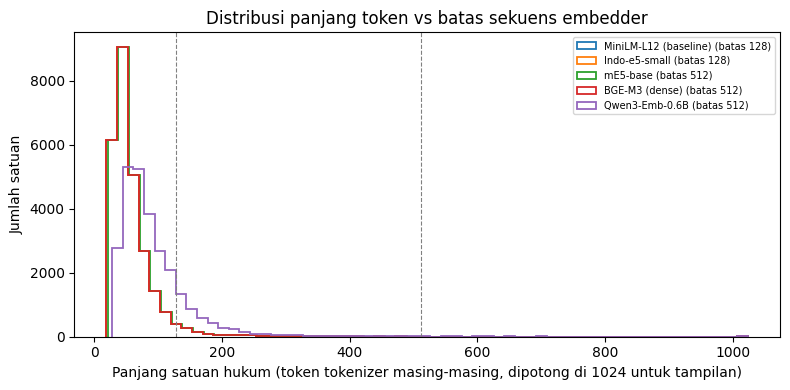

In [ ]:
# Gambar: distribusi panjang token satuan hukum terhadap batas token tiap embedder
fig, ax = plt.subplots(figsize=(8, 4))
for nama in EMBEDDER_AKTIF:
    L = korpus[f"tok_{slug(nama)}"].to_numpy()
    ax.hist(np.clip(L, 0, 1024), bins=60, histtype="step", linewidth=1.3,
            label=f"{nama} (batas {TABEL_EMBEDDER.loc[nama, 'max_seq']})")
for b in sorted({int(v) for v in TABEL_EMBEDDER["max_seq"]}):
    ax.axvline(b, ls="--", lw=0.8, color="grey")
ax.set_xlabel("Panjang satuan hukum (token tokenizer masing-masing, dipotong di 1024 untuk tampilan)")
ax.set_ylabel("Jumlah satuan")
ax.set_title("Distribusi panjang token vs batas sekuens embedder")
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG_DIR / "gbr1_panjang_token.png", dpi=300, bbox_inches="tight")
plt.show()

## §6 — Retrieval: BM25, Dense, Hybrid (RRF), Graph-RAG
Fungsi bekerja dengan indeks kueri dan nama embedder agar skor BM25 dan dense cukup dihitung sekali.
Logika Hybrid dan Graph-RAG (termasuk fusi 3 arah dengan α graf) identik Exp_03; yang ditambahkan hanya
**atribusi keluarga sisi**: setiap kandidat graf dicatat keluarga sisi yang memberi kontribusi terbesar.

In [ ]:
PETA = korpus.set_index("chunk_id")
_DENSE_CACHE = {}


def dense_top(qi: int, emb: str, k: int):
    key = (qi, emb)
    if key not in _DENSE_CACHE:
        skor = EMB[emb] @ QEMB[emb][qi]
        idx = top_idx(skor, max(K_KANDIDAT, K_EVAL))
        _DENSE_CACHE[key] = (idx, skor[idx])
    idx, s = _DENSE_CACHE[key]
    return idx[:k], s[:k]


def bm25_top(qi: int, k: int):
    skor = BM25_SKOR[qi]
    idx = top_idx(skor, k)
    return idx, skor[idx]


def retrieve_bm25(qi: int, emb=None, k: int = K_EVAL) -> list:
    return [(CHUNK_IDS[i], "bm25") for i in bm25_top(qi, k)[0]]


def retrieve_dense(qi: int, emb: str, k: int = K_EVAL) -> list:
    return [(CHUNK_IDS[i], "dense") for i in dense_top(qi, emb, k)[0]]


def hybrid_rrf(qi: int, emb: str, k: int) -> list:
    """RRF Dense + BM25 (Exp_03 §3). Kembalikan [(idx, skor_rrf)] terurut."""
    rd = dense_top(qi, emb, K_KANDIDAT)[0]
    rb = bm25_top(qi, K_KANDIDAT)[0]
    rrf = defaultdict(float)
    for p, i in enumerate(rd):
        rrf[int(i)] += 1 / (RRF_K + p + 1)
    for p, i in enumerate(rb):
        rrf[int(i)] += 1 / (RRF_K + p + 1)
    top = sorted(rrf, key=lambda i: (-rrf[i], i))[:k]
    return [(i, rrf[i]) for i in top]


def retrieve_hybrid(qi: int, emb: str, k: int = K_EVAL) -> list:
    return [(CHUNK_IDS[i], "hybrid") for i, _ in hybrid_rrf(qi, emb, k)]


def perluas_graf(seed_ids: list, bobot_seed: dict, aktif_sisi=SEMUA_SISI) -> tuple:
    """Ekspansi graf Exp_03 (perluas_graf_v2) + atribusi keluarga sisi per kandidat."""
    skor_graf, kontrib = {}, defaultdict(lambda: defaultdict(float))
    for cid in seed_ids:
        if cid not in KG:
            continue
        kandidat = []  # (chunk, bobot, keluarga)
        for p in KG.predecessors(cid):
            if KG.nodes[p].get("tipe") != "pasal":
                continue
            if "memuat" in aktif_sisi:
                kandidat += [(c, W_SISI["memuat"], "memuat") for c in KG.successors(p)
                             if KG.nodes[c].get("tipe") == "satuan" and c != cid]
            if "merujuk" in aktif_sisi:
                terkait = ([v for _, v, d in KG.out_edges(p, data=True) if d.get("rel") == "merujuk"] +
                           [u for u, _, d in KG.in_edges(p, data=True) if d.get("rel") == "merujuk"])
                for pt in terkait:
                    kandidat += [(c, W_SISI["merujuk"], "merujuk") for c in KG.successors(pt)
                                 if KG.nodes[c].get("tipe") == "satuan"]
            if "merujuk_dokumen" in aktif_sisi:
                doc_asal = cid.split("__")[0]
                if doc_asal in KG:
                    for _, dt, d in KG.out_edges(doc_asal, data=True):
                        if d.get("rel") != "merujuk_dokumen":
                            continue
                        pku = f"{dt}::P1"
                        if pku in KG:
                            kandidat += [(c, W_SISI["merujuk_dokumen"], "merujuk_dokumen") for c in KG.successors(pku)
                                         if KG.nodes[c].get("tipe") == "satuan"]
        if "menyebut" in aktif_sisi:
            for e in KG.successors(cid):
                if KG.nodes[e].get("tipe") == "entitas":
                    w_ent = W_SISI["menyebut"] * (1.0 / math.log2(max(KG.in_degree(e), 2)))
                    kandidat += [(c, w_ent, "menyebut") for c in KG.predecessors(e)
                                 if KG.nodes[c].get("tipe") == "satuan" and c != cid]
        terbaik = {}
        for c, w, fam in kandidat:
            if c not in terbaik or w > terbaik[c][0]:
                terbaik[c] = (w, fam)
        for c, (w, fam) in sorted(terbaik.items(), key=lambda x: (-x[1][0], x[0]))[:MAKS_PER_SEED]:
            kon = bobot_seed[cid] * DECAY * w
            skor_graf[c] = skor_graf.get(c, 0.0) + kon
            kontrib[c][fam] += kon
    keluarga = {c: max(f.items(), key=lambda x: x[1])[0] for c, f in kontrib.items()}
    return skor_graf, keluarga


def retrieve_graphrag(qi: int, emb: str, k: int = K_EVAL, aktif_sisi=SEMUA_SISI) -> list:
    """Graph-RAG Exp_03: hybrid → 6 seed → ekspansi → fusi (skor RRF seed + α·RRF peringkat graf)."""
    seed = hybrid_rrf(qi, emb, max(k, K_SEED * 2))
    if not seed:
        return []
    top_seed = seed[:K_SEED]
    smax = max(s for _, s in top_seed)
    bobot = {CHUNK_IDS[i]: s / smax for i, s in top_seed}
    skor_eks, keluarga = perluas_graf([CHUNK_IDS[i] for i, _ in top_seed], bobot, aktif_sisi)
    gabung = {CHUNK_IDS[i]: s for i, s in seed}
    for rg, cid in enumerate(sorted(skor_eks, key=lambda c: (-skor_eks[c], c))):
        gabung[cid] = gabung.get(cid, 0.0) + ALPHA_GRAF / (RRF_K + rg + 1)
    urut = sorted(gabung, key=lambda c: (-gabung[c], c))[:k]
    seed_set = {CHUNK_IDS[i] for i, _ in top_seed}
    return [(c, "seed" if c in seed_set else f"graf:{keluarga.get(c, 'hybrid')}") for c in urut]


# Uji cepat
print(retrieve_graphrag(0, BASELINE, k=5))

[('UU_36_1999__P29', 'seed'), ('Permen_5_2021__P175', 'seed'), ('PP_52_2000__P33__0', 'seed'), ('Permen_5_2021__P218__a2__hb', 'seed'), ('Permen_5_2021__P125__a1__0', 'seed')]


## §7 — Eksperimen Faktorial: Menjalankan Seluruh Konfigurasi (K1)
Konfigurasi = BM25 + (embedder × {Dense, Hybrid, Graph-RAG}). Setiap baris hasil = satu kueri × satu
konfigurasi × satu granularitas. Hasil mentah disimpan agar seluruh tabel tesis dapat ditelusuri.

In [ ]:
PENDEKATAN = {"Dense": retrieve_dense, "Hybrid": retrieve_hybrid, "Graph-RAG": retrieve_graphrag}
URUT_PENDEKATAN = ["BM25", "Dense", "Hybrid", "Graph-RAG"]


def jalankan(fn, emb, nama_emb, nama_pendekatan, **kw):
    rows, pred_simpan = [], {}
    for qi, g in gold.iterrows():
        t0 = time.perf_counter()
        hasil = fn(qi, emb, K_EVAL, **kw)
        dt = time.perf_counter() - t0
        ids = [c for c, _ in hasil]
        pred_simpan[g["kueri_id"]] = hasil
        for gran in ("satuan", "pasal"):
            rows.append({"embedder": nama_emb, "pendekatan": nama_pendekatan, "granularitas": gran,
                         "kueri_id": g["kueri_id"], "jenis_kueri": g["jenis_kueri"],
                         "latensi_ms": dt * 1000, **metrik_kueri(ids, g["relevan_list"], gran)})
    return rows, pred_simpan


DETAIL, PRED = [], {}
r, PRED[("BM25", "BM25")] = jalankan(retrieve_bm25, None, "— (BM25)", "BM25")
DETAIL += r
for emb in EMBEDDER_AKTIF:
    for nm, fn in PENDEKATAN.items():
        r, PRED[(emb, nm)] = jalankan(fn, emb, emb, nm)
        DETAIL += r
    print(f"selesai: {emb}")
DETAIL = pd.DataFrame(DETAIL)
# latensi BM25 = waktu skor (dihitung di §4) + pengurutan
DETAIL.loc[DETAIL.pendekatan == "BM25", "latensi_ms"] += BM25_WAKTU * 1000
DETAIL["konfigurasi"] = np.where(DETAIL.pendekatan == "BM25", "BM25",
                                 DETAIL.embedder + " | " + DETAIL.pendekatan)
DETAIL.to_csv(EXP_DIR / f"detail_per_kueri_{TIMESTAMP}.csv", index=False, encoding="utf-8-sig")
print(DETAIL.shape)

selesai: MiniLM-L12 (baseline)
selesai: Indo-e5-small
selesai: mE5-base
selesai: BGE-M3 (dense)
selesai: Qwen3-Emb-0.6B
(1472, 20)


In [ ]:
METRIK_UTAMA = ["MRR", "nDCG@10", "Recall@5", "Recall@10", "Hit@5", "Hit@10", "Precision@10"]


def tabel_ringkas(gran: str, subset=None) -> pd.DataFrame:
    d = DETAIL[DETAIL.granularitas == gran]
    if subset is not None:
        d = d[d.jenis_kueri == subset]
    t = d.groupby(["embedder", "pendekatan"])[METRIK_UTAMA + ["latensi_ms"]].mean()
    ci = d.groupby(["embedder", "pendekatan"])["nDCG@10"].apply(lambda x: "%.3f–%.3f" % boot_ci_mean(x.to_numpy()))
    t["CI95 nDCG@10"] = ci
    t = t.reset_index()
    t["pendekatan"] = pd.Categorical(t["pendekatan"], URUT_PENDEKATAN, ordered=True)
    return t.sort_values(["pendekatan", "nDCG@10"], ascending=[True, False]).set_index(["pendekatan", "embedder"]).round(4)


for gran in ("satuan", "pasal"):
    print(f"\nTabel 2{'a' if gran=='satuan' else 'b'}. Hasil faktorial — granularitas {gran} (rata-rata {gold.shape[0]} kueri)")
    display(tabel_ringkas(gran))


Tabel 2a. Hasil faktorial — granularitas satuan (rata-rata 46 kueri)


MRR  nDCG@10  Recall@5  Recall@10   Hit@5  Hit@10  Precision@10  latensi_ms CI95 nDCG@10
pendekatan embedder                                                                                                          
BM25       — (BM25)               0.5721   0.3458    0.2147     0.3269  0.7826  0.8261        0.2457     59.2869  0.277–0.415
Dense      mE5-base               0.7140   0.4559    0.2801     0.4191  0.8478  0.9130        0.3239      5.7096  0.384–0.527
           BGE-M3 (dense)         0.6831   0.4141    0.2652     0.3839  0.8261  0.9130        0.2870      7.3396  0.348–0.483
           Qwen3-Emb-0.6B         0.6558   0.3829    0.2388     0.3482  0.8043  0.8478        0.2609      7.9281  0.313–0.452
           Indo-e5-small          0.5647   0.3159    0.2025     0.2900  0.7826  0.8261        0.2217      2.3664  0.255–0.378
           MiniLM-L12 (baseline)  0.4426   0.2361    0.1497     0.2182  0.6087  0.6957        0.1652      2.2121  0.172–0.302
Hybrid     mE5-base               0.6720   0.4477    0.2793     0.4225  0.8261  0.8913        0.3304      0.3319  0.376–0.520
           BGE-M3 (dense)         0.6607   0.4231    0.2712     0.3985  0.8043  0.8913        0.3065      0.2900  0.352–0.492
           Indo-e5-small          0.7101   0.4017    0.2450     0.3599  0.8261  0.8913        0.2804      0.2955  0.335–0.468
           Qwen3-Emb-0.6B         0.6508   0.3911    0.2436     0.3650  0.7826  0.8696        0.2804      0.2946  0.325–0.457
           MiniLM-L12 (baseline)  0.6281   0.3333    0.2078     0.3119  0.8478  0.8696        0.2348      0.3163  0.275–0.393
Graph-RAG  mE5-base               0.6771   0.4682    0.2907     0.4404  0.8043  0.9130        0.3478      4.2179  0.394–0.544
           BGE-M3 (dense)         0.6836   0.4383    0.2980     0.3928  0.8478  0.9130        0.3043      4.4813  0.367–0.508
           Qwen3-Emb-0.6B         0.6506   0.4030    0.2484     0.3705  0.8043  0.8696        0.2826      4.1765  0.335–0.472
           Indo-e5-small          0.6515   0.3881    0.2544     0.3497  0.8261  0.8913        0.2739      3.7568  0.322–0.454
           MiniLM-L12 (baseline)  0.5843   0.3405    0.2287     0.3085  0.8261  0.8478        0.2391      3.4957  0.276–0.407


Tabel 2b. Hasil faktorial — granularitas pasal (rata-rata 46 kueri)


MRR  nDCG@10  Recall@5  Recall@10   Hit@5  Hit@10  Precision@10  latensi_ms CI95 nDCG@10
pendekatan embedder                                                                                                          
BM25       — (BM25)               0.6457   0.4423    0.4096     0.4543  0.8913  0.8913        0.1761     59.2869  0.372–0.512
Dense      BGE-M3 (dense)         0.7414   0.5729    0.5159     0.5999  0.9130  0.9565        0.2370      7.3396  0.498–0.646
           mE5-base               0.7761   0.5707    0.5071     0.5478  0.8696  0.9130        0.2239      5.7096  0.486–0.654
           Qwen3-Emb-0.6B         0.6884   0.4878    0.4410     0.4916  0.8478  0.8696        0.1913      7.9281  0.403–0.571
           Indo-e5-small          0.6705   0.4564    0.3956     0.4567  0.8478  0.8696        0.1804      2.3664  0.378–0.537
           MiniLM-L12 (baseline)  0.5135   0.3537    0.3097     0.3687  0.6739  0.7609        0.1413      2.2121  0.268–0.443
Hybrid     BGE-M3 (dense)         0.7507   0.5551    0.4873     0.5767  0.9348  0.9565        0.2304      0.2900  0.480–0.627
           mE5-base               0.7296   0.5512    0.4653     0.5671  0.8478  0.9565        0.2283      0.3319  0.472–0.627
           Indo-e5-small          0.7629   0.5365    0.4638     0.5460  0.9130  0.9565        0.2196      0.2955  0.467–0.605
           Qwen3-Emb-0.6B         0.6917   0.4857    0.4334     0.4950  0.8913  0.9130        0.1935      0.2946  0.407–0.562
           MiniLM-L12 (baseline)  0.7062   0.4678    0.4074     0.4749  0.8913  0.9130        0.1848      0.3163  0.395–0.543
Graph-RAG  mE5-base               0.7984   0.5699    0.4664     0.5573  0.8696  0.9565        0.2239      4.2179  0.496–0.638
           BGE-M3 (dense)         0.8069   0.5689    0.4952     0.5626  0.9565  0.9783        0.2239      4.4813  0.500–0.633
           Indo-e5-small          0.7890   0.5337    0.4745     0.5176  0.9348  0.9565        0.2065      3.7568  0.465–0.602
           Qwen3-Emb-0.6B         0.7514   0.4988    0.4242     0.4823  0.8913  0.9130        0.1891      4.1765  0.427–0.569
           MiniLM-L12 (baseline)  0.7192   0.4779    0.4106     0.4641  0.8696  0.8913        0.1826      3.4957  0.404–0.551

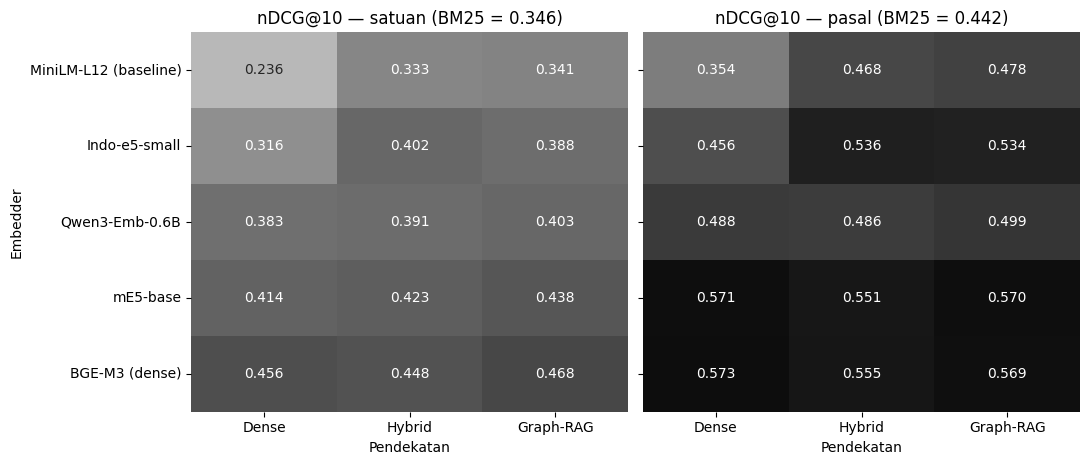

In [ ]:
# Heatmap embedder × pendekatan (nDCG@10), dua granularitas
fig, axes = plt.subplots(1, 2, figsize=(11, 0.55 * len(EMBEDDER_AKTIF) + 2), sharey=True)
for ax, gran in zip(axes, ("satuan", "pasal")):
    d = DETAIL[(DETAIL.granularitas == gran) & (DETAIL.pendekatan != "BM25")]
    pv = d.pivot_table(index="embedder", columns="pendekatan", values="nDCG@10").reindex(columns=["Dense", "Hybrid", "Graph-RAG"])
    pv = pv.loc[pv["Dense"].sort_values().index]
    bm = DETAIL[(DETAIL.granularitas == gran) & (DETAIL.pendekatan == "BM25")]["nDCG@10"].mean()
    sns.heatmap(pv, annot=True, fmt=".3f", cmap="Greys", cbar=False, ax=ax, vmin=0, vmax=max(0.6, pv.values.max()))
    ax.set_title(f"nDCG@10 — {gran} (BM25 = {bm:.3f})")
    ax.set_xlabel("Pendekatan"); ax.set_ylabel("Embedder" if gran == "satuan" else "")
plt.tight_layout()
plt.savefig(FIG_DIR / "gbr2_heatmap_faktorial.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Uji omnibus Friedman atas seluruh konfigurasi (nDCG@10)
FRIEDMAN = []
for gran in ("satuan", "pasal"):
    lebar = DETAIL[DETAIL.granularitas == gran].pivot(index="kueri_id", columns="konfigurasi", values="nDCG@10")
    st, p = stats.friedmanchisquare(*[lebar[c].to_numpy() for c in lebar.columns])
    peringkat = lebar.rank(axis=1, ascending=False).mean().sort_values()
    FRIEDMAN.append({"granularitas": gran, "k_konfigurasi": lebar.shape[1], "n_kueri": lebar.shape[0],
                     "chi2": round(st, 3), "p": p})
    print(f"[{gran}] Friedman chi2={st:.2f}, p={p:.2e}. Rata-rata peringkat terbaik:")
    print(peringkat.head(6).round(2).to_string())
FRIEDMAN = pd.DataFrame(FRIEDMAN)

[satuan] Friedman chi2=91.72, p=4.74e-13. Rata-rata peringkat terbaik:
konfigurasi
mE5-base | Graph-RAG          6.00
BGE-M3 (dense) | Graph-RAG    6.30
mE5-base | Hybrid             6.68
mE5-base | Dense              6.98
BGE-M3 (dense) | Hybrid       7.55
BGE-M3 (dense) | Dense        8.21
[pasal] Friedman chi2=64.27, p=4.59e-08. Rata-rata peringkat terbaik:
konfigurasi
BGE-M3 (dense) | Graph-RAG    6.91
mE5-base | Graph-RAG          7.00
mE5-base | Dense              7.02
BGE-M3 (dense) | Dense        7.14
BGE-M3 (dense) | Hybrid       7.39
mE5-base | Hybrid             7.45


**Interpretasi (isi setelah dijalankan).** Berdasarkan Tabel 2, … konfigurasi dengan nDCG@10 tertinggi pada
granularitas satuan adalah …; uji Friedman menunjukkan … Bandingkan baris MiniLM dengan Exp_03 untuk
memastikan replikasi (selisih seharusnya ≈ 0).

## §8 — Efek Embedder, Efek Graf, dan Interaksinya (K1, K2)
Pertanyaan kunci: **apakah embedder yang lebih baik mengubah nilai tambah graf?**
Keluarga kontras (a) mengukur efek pendekatan di dalam tiap embedder; (b) efek embedder per pendekatan
terhadap MiniLM; (c) konfigurasi terbaik terhadap BM25.

In [ ]:
METRIK_UJI = "nDCG@10"
KONTRAS = {}
for gran in ("satuan", "pasal"):
    lebar = DETAIL[DETAIL.granularitas == gran].pivot(index="kueri_id", columns="konfigurasi", values=METRIK_UJI)
    pa = []
    for e in EMBEDDER_AKTIF:
        pa += [(f"{e} | Hybrid", f"{e} | Dense"), (f"{e} | Graph-RAG", f"{e} | Hybrid"),
               (f"{e} | Graph-RAG", f"{e} | Dense")]
    ka = kontras(lebar, pa, "a: pendekatan dalam embedder", METRIK_UJI)
    pb = [(f"{e} | {p}", f"{BASELINE} | {p}") for p in ("Dense", "Hybrid", "Graph-RAG")
          for e in EMBEDDER_AKTIF if e != BASELINE]
    kb = kontras(lebar, pb, "b: embedder vs MiniLM", METRIK_UJI) if pb else pd.DataFrame()
    terbaik = lebar.drop(columns=["BM25"]).mean().idxmax()
    kc = kontras(lebar, [(terbaik, "BM25"), (f"{BASELINE} | Graph-RAG", "BM25")], "c: vs BM25", METRIK_UJI)
    KONTRAS[gran] = pd.concat([ka, kb, kc], ignore_index=True)
    KONTRAS[gran].insert(0, "granularitas", gran)

kol = ["keluarga", "A", "B", "delta", "CI95_lo", "CI95_hi", "naik", "turun", "p_wilcoxon", "p_holm", "r_rb", "signifikan"]
print("Tabel 3. Kontras terencana (nDCG@10, granularitas satuan)")
display(KONTRAS["satuan"][kol].round(4))

Tabel 3. Kontras terencana (nDCG@10, granularitas satuan)


,keluarga,A,B,delta,CI95_lo,CI95_hi,naik,turun,p_wilcoxon,p_holm,r_rb,signifikan
0,a: pendekatan dalam embedder,MiniLM-L12 (baseline) | Hybrid,MiniLM-L12 (baseline) | Dense,0.0972,0.0573,0.1400,32,8,0.0001,0.0011,0.7073,True
1,a: pendekatan dalam embedder,MiniLM-L12 (baseline) | Graph-RAG,MiniLM-L12 (baseline) | Hybrid,0.0072,-0.0198,0.0342,19,14,0.4367,1.0000,0.1373,False
2,a: pendekatan dalam embedder,MiniLM-L12 (baseline) | Graph-RAG,MiniLM-L12 (baseline) | Dense,0.1044,0.0614,0.1497,32,9,0.0001,0.0011,0.7073,True
3,a: pendekatan dalam embedder,Indo-e5-small | Hybrid,Indo-e5-small | Dense,0.0858,0.0286,0.1412,32,9,0.0004,0.0056,0.6144,True
4,a: pendekatan dalam embedder,Indo-e5-small | Graph-RAG,Indo-e5-small | Hybrid,-0.0136,-0.0386,0.0092,17,18,0.6497,1.0000,-0.1143,False
5,a: pendekatan dalam embedder,Indo-e5-small | Graph-RAG,Indo-e5-small | Dense,0.0722,0.0131,0.1312,31,11,0.0025,0.0302,0.5238,True
6,a: pendekatan dalam embedder,mE5-base | Hybrid,mE5-base | Dense,-0.0082,-0.0680,0.0477,18,23,0.7431,1.0000,-0.0407,False
7,a: pendekatan dalam embedder,mE5-base | Graph-RAG,mE5-base | Hybrid,0.0204,-0.0061,0.0473,21,11,0.0705,0.7048,0.3598,False
8,a: pendekatan dalam embedder,mE5-base | Graph-RAG,mE5-base | Dense,0.0123,-0.0420,0.0632,22,19,0.5406,1.0000,0.1127,False
9,a: pendekatan dalam embedder,BGE-M3 (dense) | Hybrid,BGE-M3 (dense) | Dense,0.0090,-0.0567,0.0679,25,16,0.3148,1.0000,0.1614,False


Tabel 4. Nilai tambah fusi BM25 dan graf per embedder


,granularitas,embedder,nDCG_dense,nDCG_hybrid,nDCG_graph,Δ_hybrid−dense,p_holm_hd,Δ_graph−hybrid,CI95,p_holm_gh,naik/turun_gh
0,satuan,MiniLM-L12 (baseline),0.2361,0.3333,0.3405,0.0972,0.0011,0.0072,"[-0.020, 0.034]",1.0000,19/14
1,satuan,Indo-e5-small,0.3159,0.4017,0.3881,0.0858,0.0056,-0.0136,"[-0.039, 0.009]",1.0000,17/18
2,satuan,mE5-base,0.4559,0.4477,0.4682,-0.0082,1.0000,0.0204,"[-0.006, 0.047]",0.7048,21/11
3,satuan,BGE-M3 (dense),0.4141,0.4231,0.4383,0.0090,1.0000,0.0152,"[-0.009, 0.040]",0.4696,24/9
4,satuan,Qwen3-Emb-0.6B,0.3829,0.3911,0.4030,0.0082,1.0000,0.0119,"[-0.011, 0.037]",1.0000,15/16
5,pasal,MiniLM-L12 (baseline),0.3537,0.4678,0.4779,0.1141,0.0106,0.0101,"[-0.024, 0.045]",1.0000,13/11
6,pasal,Indo-e5-small,0.4564,0.5365,0.5337,0.0801,0.0787,-0.0027,"[-0.028, 0.025]",1.0000,10/11
7,pasal,mE5-base,0.5707,0.5512,0.5699,-0.0195,1.0000,0.0187,"[-0.005, 0.043]",1.0000,13/8
8,pasal,BGE-M3 (dense),0.5729,0.5551,0.5689,-0.0178,1.0000,0.0138,"[-0.010, 0.038]",1.0000,15/8
9,pasal,Qwen3-Emb-0.6B,0.4878,0.4857,0.4988,-0.0021,1.0000,0.0131,"[-0.012, 0.040]",1.0000,11/9


[satuan] Spearman(kualitas dense, Δ graf) = 0.90 (p=0.037, n=5 embedder — deskriptif)
[pasal] Spearman(kualitas dense, Δ graf) = 0.80 (p=0.104, n=5 embedder — deskriptif)


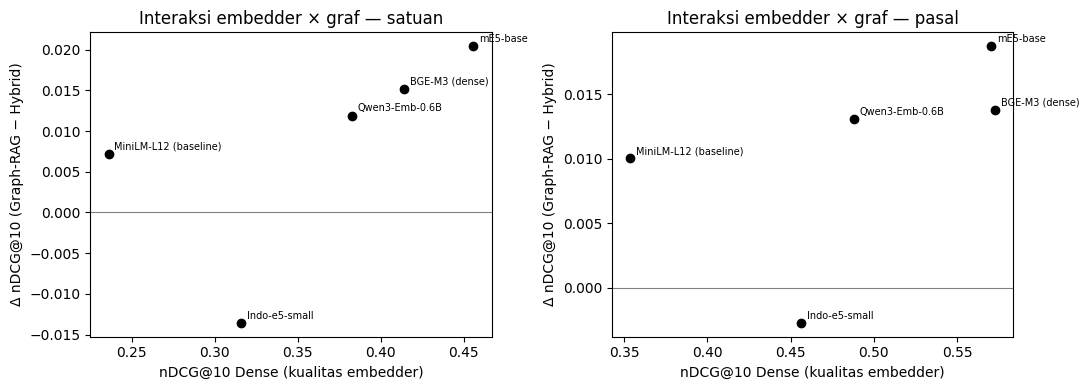

In [ ]:
# Efek graf per embedder: Δ(Graph-RAG − Hybrid) vs kualitas dense → apakah nilai tambah graf mengecil?
EFEK = []
for gran in ("satuan", "pasal"):
    k = KONTRAS[gran]
    for e in EMBEDDER_AKTIF:
        g_h = k[(k.A == f"{e} | Graph-RAG") & (k.B == f"{e} | Hybrid")].iloc[0]
        h_d = k[(k.A == f"{e} | Hybrid") & (k.B == f"{e} | Dense")].iloc[0]
        EFEK.append({"granularitas": gran, "embedder": e, "nDCG_dense": h_d.mean_B,
                     "nDCG_hybrid": g_h.mean_B, "nDCG_graph": g_h.mean_A,
                     "Δ_hybrid−dense": h_d.delta, "p_holm_hd": h_d.p_holm,
                     "Δ_graph−hybrid": g_h.delta, "CI95": f"[{g_h.CI95_lo:.3f}, {g_h.CI95_hi:.3f}]",
                     "p_holm_gh": g_h.p_holm, "naik/turun_gh": f"{g_h.naik}/{g_h.turun}"})
EFEK = pd.DataFrame(EFEK)
print("Tabel 4. Nilai tambah fusi BM25 dan graf per embedder")
display(EFEK.round(4))

for gran in ("satuan", "pasal"):
    e = EFEK[EFEK.granularitas == gran]
    if len(e) >= 4:
        rho, p = stats.spearmanr(e["nDCG_dense"], e["Δ_graph−hybrid"])
        print(f"[{gran}] Spearman(kualitas dense, Δ graf) = {rho:.2f} (p={p:.3f}, n={len(e)} embedder — deskriptif)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, gran in zip(axes, ("satuan", "pasal")):
    e = EFEK[EFEK.granularitas == gran]
    ax.axhline(0, color="grey", lw=0.8)
    ax.scatter(e["nDCG_dense"], e["Δ_graph−hybrid"], color="black")
    for _, r in e.iterrows():
        ax.annotate(r["embedder"], (r["nDCG_dense"], r["Δ_graph−hybrid"]), fontsize=7,
                    xytext=(4, 3), textcoords="offset points")
    ax.set_xlabel("nDCG@10 Dense (kualitas embedder)")
    ax.set_ylabel("Δ nDCG@10 (Graph-RAG − Hybrid)")
    ax.set_title(f"Interaksi embedder × graf — {gran}")
plt.tight_layout()
plt.savefig(FIG_DIR / "gbr3_interaksi_embedder_graf.png", dpi=300, bbox_inches="tight")
plt.show()

**Cara membaca.** Bila titik turun ke kanan (ρ negatif), nilai tambah graf mengecil ketika dense membaik:
graf berperan sebagai *kompensator* seed yang lemah. Bila naik (ρ positif), graf dan embedder saling
*menguatkan* (seed yang lebih akurat menghasilkan ekspansi yang lebih relevan). Dengan sedikit embedder,
ρ hanya deskriptif; kesimpulan inferensial bersandar pada Tabel 4 (Wilcoxon + Holm per embedder).

## §9 — Granularitas Satuan Hukum vs Pasal (K3)
Mengukur (i) seberapa besar skor naik dari satuan ke pasal untuk tiap pendekatan, dan (ii) apakah
**urutan** konfigurasi berubah (Kendall τ antar-peringkat). Kenaikan yang lebih besar pada Graph-RAG
menandakan graf membawa pasal yang benar tetapi bukan ayat/butir yang persis.

In [ ]:
a = DETAIL[DETAIL.granularitas == "satuan"].groupby("konfigurasi")[["MRR", "nDCG@10", "Hit@10"]].mean()
b = DETAIL[DETAIL.granularitas == "pasal"].groupby("konfigurasi")[["MRR", "nDCG@10", "Hit@10"]].mean()
GRAN = pd.concat({"satuan": a, "pasal": b}, axis=1)
for m in ("MRR", "nDCG@10", "Hit@10"):
    GRAN[("Δ pasal−satuan", m)] = GRAN[("pasal", m)] - GRAN[("satuan", m)]
GRAN[("peringkat", "satuan")] = a["nDCG@10"].rank(ascending=False)
GRAN[("peringkat", "pasal")] = b["nDCG@10"].rank(ascending=False)
tau, p_tau = stats.kendalltau(GRAN[("peringkat", "satuan")], GRAN[("peringkat", "pasal")])
print(f"Kendall τ peringkat konfigurasi satuan vs pasal = {tau:.3f} (p={p_tau:.3f})")
print("Tabel 5. Pengaruh granularitas")
display(GRAN.sort_values(("pasal", "nDCG@10"), ascending=False).round(4))

# Uji: apakah kenaikan (pasal − satuan) Graph-RAG lebih besar daripada Hybrid? (per embedder)
UJI_GRAN = []
for e in EMBEDDER_AKTIF:
    def gain(pend):
        s = DETAIL[(DETAIL.konfigurasi == f"{e} | {pend}")].pivot(index="kueri_id", columns="granularitas", values="nDCG@10")
        return (s["pasal"] - s["satuan"]).sort_index()
    gg, gh = gain("Graph-RAG"), gain("Hybrid")
    UJI_GRAN.append({"embedder": e, "gain_graph": gg.mean(), "gain_hybrid": gh.mean(),
                     "selisih": gg.mean() - gh.mean(), "p_wilcoxon": wilcoxon_aman(gg, gh)})
UJI_GRAN = pd.DataFrame(UJI_GRAN)
UJI_GRAN["p_holm"] = holm(UJI_GRAN["p_wilcoxon"])
display(UJI_GRAN.round(4))

Kendall τ peringkat konfigurasi satuan vs pasal = 0.750 (p=0.000)
Tabel 5. Pengaruh granularitas


satuan                   pasal                 Δ pasal−satuan                 peringkat      
                                      MRR nDCG@10  Hit@10     MRR nDCG@10  Hit@10            MRR nDCG@10  Hit@10    satuan pasal
konfigurasi                                                                                                                     
BGE-M3 (dense) | Dense             0.6831  0.4141  0.9130  0.7414  0.5729  0.9565         0.0582  0.1588  0.0435       6.0   1.0
mE5-base | Dense                   0.7140  0.4559  0.9130  0.7761  0.5707  0.9130         0.0621  0.1148  0.0000       2.0   2.0
mE5-base | Graph-RAG               0.6771  0.4682  0.9130  0.7984  0.5699  0.9565         0.1213  0.1018  0.0435       1.0   3.0
BGE-M3 (dense) | Graph-RAG         0.6836  0.4383  0.9130  0.8069  0.5689  0.9783         0.1233  0.1306  0.0652       4.0   4.0
BGE-M3 (dense) | Hybrid            0.6607  0.4231  0.8913  0.7507  0.5551  0.9565         0.0900  0.1320  0.0652       5.0   5.0
mE5-base | Hybrid                  0.6720  0.4477  0.8913  0.7296  0.5512  0.9565         0.0575  0.1035  0.0652       3.0   6.0
Indo-e5-small | Hybrid             0.7101  0.4017  0.8913  0.7629  0.5365  0.9565         0.0527  0.1348  0.0652       8.0   7.0
Indo-e5-small | Graph-RAG          0.6515  0.3881  0.8913  0.7890  0.5337  0.9565         0.1375  0.1456  0.0652      10.0   8.0
Qwen3-Emb-0.6B | Graph-RAG         0.6506  0.4030  0.8696  0.7514  0.4988  0.9130         0.1009  0.0958  0.0435       7.0   9.0
Qwen3-Emb-0.6B | Dense             0.6558  0.3829  0.8478  0.6884  0.4878  0.8696         0.0326  0.1049  0.0217      11.0  10.0
Qwen3-Emb-0.6B | Hybrid            0.6508  0.3911  0.8696  0.6917  0.4857  0.9130         0.0409  0.0947  0.0435       9.0  11.0
MiniLM-L12 (baseline) | Graph-RAG  0.5843  0.3405  0.8478  0.7192  0.4779  0.8913         0.1349  0.1374  0.0435      13.0  12.0
MiniLM-L12 (baseline) | Hybrid     0.6281  0.3333  0.8696  0.7062  0.4678  0.9130         0.0781  0.1345  0.0435      14.0  13.0
Indo-e5-small | Dense              0.5647  0.3159  0.8261  0.6705  0.4564  0.8696         0.1058  0.1405  0.0435      15.0  14.0
BM25                               0.5721  0.3458  0.8261  0.6457  0.4423  0.8913         0.0736  0.0965  0.0652      12.0  15.0
MiniLM-L12 (baseline) | Dense      0.4426  0.2361  0.6957  0.5135  0.3537  0.7609         0.0709  0.1176  0.0652      16.0  16.0

,embedder,gain_graph,gain_hybrid,selisih,p_wilcoxon,p_holm
0,MiniLM-L12 (baseline),0.1374,0.1345,0.0029,0.5839,1.0
1,Indo-e5-small,0.1456,0.1348,0.0108,0.7429,1.0
2,mE5-base,0.1018,0.1035,-0.0017,0.7550,1.0
3,BGE-M3 (dense),0.1306,0.1320,-0.0014,0.4735,1.0
4,Qwen3-Emb-0.6B,0.0958,0.0947,0.0012,0.4656,1.0


## §10 — *Mengapa & kapan*: Mekanisme Graf dan Kondisi Kueri (K2)
1. **Kontribusi traversal**: porsi hasil graf di 10 teratas, *true positive* dari graf, serta kueri yang
   **diselamatkan** (Hit@10 Hybrid = 0 → Graph-RAG = 1) dan yang **dirugikan** (1 → 0).
2. **Reachability**: porsi satuan relevan yang berjarak ≤2 / ≤4 sisi dari seed (graf tak berarah) —
   batas atas teoretis manfaat ekspansi.
3. **Kondisi kueri**: kinerja per kelompok (a) tumpang-tindih leksikal kueri–teks relevan,
   (b) jumlah pasal relevan (proksi kebutuhan multi-pasal), (c) relevan lintas dokumen,
   (d) panjang token satuan relevan (pemotongan), (e) jenis kueri formal/awam bila tersedia.

In [ ]:
KG_UND = nx.Graph(KG.to_undirected())
MEKANISME = []
for e in EMBEDDER_AKTIF:
    tot_graf = tp_graf = selamat = rugi = 0
    r2 = r4 = n_rel = 0
    for qi, g in gold.iterrows():
        rel = set(g["relevan_list"])
        hasil_g = PRED[(e, "Graph-RAG")][g["kueri_id"]]
        hasil_h = [c for c, _ in PRED[(e, "Hybrid")][g["kueri_id"]]]
        graf = [c for c, a in hasil_g if a.startswith("graf")]
        tot_graf += len(graf)
        tp_graf += sum(c in rel for c in graf)
        hit_g = any(c in rel for c, _ in hasil_g)
        hit_h = any(c in rel for c in hasil_h)
        selamat += int(hit_g and not hit_h)
        rugi += int(hit_h and not hit_g)
        seeds = [CHUNK_IDS[i] for i, _ in hybrid_rrf(qi, e, K_SEED)]
        jarak = nx.multi_source_dijkstra_path_length(KG_UND, [s for s in seeds if s in KG_UND], cutoff=4)
        for t in rel:
            if t in ID_KORPUS:
                n_rel += 1
                d = jarak.get(t)
                r2 += int(d is not None and d <= 2)
                r4 += int(d is not None and d <= 4)
    n_top = len(gold) * K_EVAL
    MEKANISME.append({"embedder": e, "%_hasil_dari_graf": 100 * tot_graf / n_top, "TP_graf": tp_graf,
                      "presisi_graf": tp_graf / tot_graf if tot_graf else np.nan,
                      "kueri_diselamatkan": selamat, "kueri_dirugikan": rugi,
                      "%_relevan_≤2_sisi": 100 * r2 / max(n_rel, 1), "%_relevan_≤4_sisi": 100 * r4 / max(n_rel, 1)})
MEKANISME = pd.DataFrame(MEKANISME).set_index("embedder")
print("Tabel 6. Mekanisme kontribusi graf (granularitas satuan, Top-10)")
display(MEKANISME.round(2))

Tabel 6. Mekanisme kontribusi graf (granularitas satuan, Top-10)


,%_hasil_dari_graf,TP_graf,presisi_graf,kueri_diselamatkan,kueri_dirugikan,%_relevan_≤2_sisi,%_relevan_≤4_sisi
embedder,,,,,,,
MiniLM-L12 (baseline),42.83,33,0.17,0,1,51.73,87.20
Indo-e5-small,42.61,25,0.13,0,0,59.73,92.27
mE5-base,40.22,53,0.29,1,0,58.67,94.13
BGE-M3 (dense),42.83,34,0.17,1,0,62.67,94.13
Qwen3-Emb-0.6B,40.65,38,0.20,0,0,56.53,92.27


In [ ]:
# Fitur kondisi kueri (tidak bergantung sistem)
def fitur_kueri(g) -> dict:
    rel = [c for c in g["relevan_list"] if c in POS]
    tq = set(tokenisasi(g["pertanyaan"]))
    tok_rel = set(itertools.chain.from_iterable(TOKENS_KORPUS[POS[c]] for c in rel))
    tok_base = korpus.loc[[POS[c] for c in rel], f"tok_{slug(BASELINE)}"] if rel else pd.Series(dtype=float)
    return {"kueri_id": g["kueri_id"], "jenis_kueri": g["jenis_kueri"],
            "overlap_leksikal": len(tq & tok_rel) / len(tq) if tq else 0.0,
            "n_pasal_relevan": len({cid_ke_pasal(c) for c in g["relevan_list"]}),
            "lintas_dokumen": len({c.split("__")[0] for c in g["relevan_list"]}) > 1,
            "median_token_relevan": float(np.median(tok_base)) if len(tok_base) else np.nan}


FITUR = pd.DataFrame([fitur_kueri(g) for _, g in gold.iterrows()])


def kelompok_tertil(s: pd.Series, label=("rendah", "sedang", "tinggi")) -> pd.Series:
    try:
        return pd.qcut(s.rank(method="first"), 3, labels=list(label))
    except ValueError:
        return pd.Series(["semua"] * len(s), index=s.index)


FITUR["kel_overlap"] = kelompok_tertil(FITUR["overlap_leksikal"])
FITUR["kel_multipasal"] = np.where(FITUR["n_pasal_relevan"] >= 3, "≥3 pasal", "1–2 pasal")
FITUR["kel_lintasdok"] = np.where(FITUR["lintas_dokumen"], "lintas dokumen", "satu dokumen")
FITUR["kel_panjang"] = kelompok_tertil(FITUR["median_token_relevan"], ("pendek", "sedang", "panjang"))
display(FITUR.describe(include="all").T[["count", "mean", "top", "freq"]].head(10))

,count,mean,top,freq
kueri_id,46,NaN,Q001,1
jenis_kueri,46,NaN,formal,46
overlap_leksikal,46.0,0.706386,NaN,NaN
n_pasal_relevan,46.0,4.347826,NaN,NaN
lintas_dokumen,46,NaN,True,26
median_token_relevan,46.0,54.130435,NaN,NaN
kel_overlap,46,NaN,tinggi,16
kel_multipasal,46,NaN,≥3 pasal,39
kel_lintasdok,46,NaN,lintas dokumen,26
kel_panjang,46,NaN,panjang,16


In [ ]:
def analisis_kondisi(kolom: str, embedder_list: list, gran="satuan", metrik="nDCG@10") -> pd.DataFrame:
    d = DETAIL[(DETAIL.granularitas == gran)].drop(columns="jenis_kueri").merge(FITUR[["kueri_id", kolom]], on="kueri_id")
    d = d[(d.pendekatan == "BM25") | d.embedder.isin(embedder_list)]
    t = d.pivot_table(index=kolom, columns="konfigurasi", values=metrik, aggfunc="mean", observed=False)
    t.insert(0, "n_kueri", d[d.konfigurasi == "BM25"].groupby(kolom, observed=False).size())
    return t.round(3)


# Pilih embedder pembanding: baseline + embedder dengan dense terbaik
_dense = DETAIL[(DETAIL.granularitas == "satuan") & (DETAIL.pendekatan == "Dense")].groupby("embedder")["nDCG@10"].mean()
EMB_TERBAIK_DENSE = _dense.idxmax()
EMB_BANDING = list(dict.fromkeys([BASELINE, EMB_TERBAIK_DENSE]))
KONDISI = {}
for kol, judul in [("kel_overlap", "tumpang-tindih leksikal"), ("kel_multipasal", "jumlah pasal relevan"),
                   ("kel_lintasdok", "sebaran dokumen relevan"), ("kel_panjang", "panjang token satuan relevan"),
                   ("jenis_kueri", "jenis kueri")]:
    if FITUR[kol].nunique() < 2:
        continue
    KONDISI[kol] = analisis_kondisi(kol, EMB_BANDING)
    print(f"\nTabel 7-{kol}. nDCG@10 per kondisi: {judul}")
    display(KONDISI[kol])


Tabel 7-kel_overlap. nDCG@10 per kondisi: tumpang-tindih leksikal


konfigurasi,n_kueri,BM25,MiniLM-L12 (baseline) | Dense,MiniLM-L12 (baseline) | Graph-RAG,MiniLM-L12 (baseline) | Hybrid,mE5-base | Dense,mE5-base | Graph-RAG,mE5-base | Hybrid
kel_overlap,,,,,,,,
rendah,15,0.241,0.208,0.307,0.302,0.371,0.377,0.354
sedang,15,0.302,0.237,0.333,0.333,0.489,0.478,0.432
tinggi,16,0.486,0.262,0.380,0.363,0.504,0.545,0.551



Tabel 7-kel_multipasal. nDCG@10 per kondisi: jumlah pasal relevan


konfigurasi,n_kueri,BM25,MiniLM-L12 (baseline) | Dense,MiniLM-L12 (baseline) | Graph-RAG,MiniLM-L12 (baseline) | Hybrid,mE5-base | Dense,mE5-base | Graph-RAG,mE5-base | Hybrid
kel_multipasal,,,,,,,,
1–2 pasal,7,0.483,0.284,0.421,0.46,0.477,0.555,0.540
≥3 pasal,39,0.321,0.228,0.326,0.31,0.452,0.453,0.431



Tabel 7-kel_lintasdok. nDCG@10 per kondisi: sebaran dokumen relevan


konfigurasi,n_kueri,BM25,MiniLM-L12 (baseline) | Dense,MiniLM-L12 (baseline) | Graph-RAG,MiniLM-L12 (baseline) | Hybrid,mE5-base | Dense,mE5-base | Graph-RAG,mE5-base | Hybrid
kel_lintasdok,,,,,,,,
lintas dokumen,26,0.329,0.196,0.305,0.305,0.464,0.469,0.450
satu dokumen,20,0.367,0.288,0.386,0.371,0.445,0.467,0.444



Tabel 7-kel_panjang. nDCG@10 per kondisi: panjang token satuan relevan


konfigurasi,n_kueri,BM25,MiniLM-L12 (baseline) | Dense,MiniLM-L12 (baseline) | Graph-RAG,MiniLM-L12 (baseline) | Hybrid,mE5-base | Dense,mE5-base | Graph-RAG,mE5-base | Hybrid
kel_panjang,,,,,,,,
pendek,15,0.307,0.239,0.355,0.314,0.380,0.422,0.384
sedang,15,0.457,0.260,0.368,0.387,0.546,0.624,0.599
panjang,16,0.278,0.210,0.300,0.302,0.443,0.365,0.366


Tabel 8. Uji per kondisi (n per kelompok kecil → tafsirkan sebagai eksploratif)


,kondisi,kelompok,A,B,n,delta,p_wilcoxon,p_holm
0,kel_overlap,rendah,MiniLM-L12 (baseline) | Graph-RAG,MiniLM-L12 (baseline) | Hybrid,15,0.0042,0.6679,1.0000
1,kel_overlap,rendah,MiniLM-L12 (baseline) | Dense,BM25,15,-0.0330,0.4946,1.0000
2,kel_overlap,rendah,mE5-base | Graph-RAG,mE5-base | Hybrid,15,0.0228,0.5493,1.0000
3,kel_overlap,rendah,mE5-base | Dense,BM25,15,0.1302,0.0184,0.1936
4,kel_overlap,sedang,MiniLM-L12 (baseline) | Graph-RAG,MiniLM-L12 (baseline) | Hybrid,15,0.0001,0.6489,1.0000
5,kel_overlap,sedang,MiniLM-L12 (baseline) | Dense,BM25,15,-0.0645,0.5137,1.0000
6,kel_overlap,sedang,mE5-base | Graph-RAG,mE5-base | Hybrid,15,0.0463,0.0176,0.1936
7,kel_overlap,sedang,mE5-base | Dense,BM25,15,0.1875,0.0649,0.5842
8,kel_overlap,tinggi,MiniLM-L12 (baseline) | Graph-RAG,MiniLM-L12 (baseline) | Hybrid,16,0.0166,0.5692,1.0000
9,kel_overlap,tinggi,MiniLM-L12 (baseline) | Dense,BM25,16,-0.2239,0.0077,0.0928


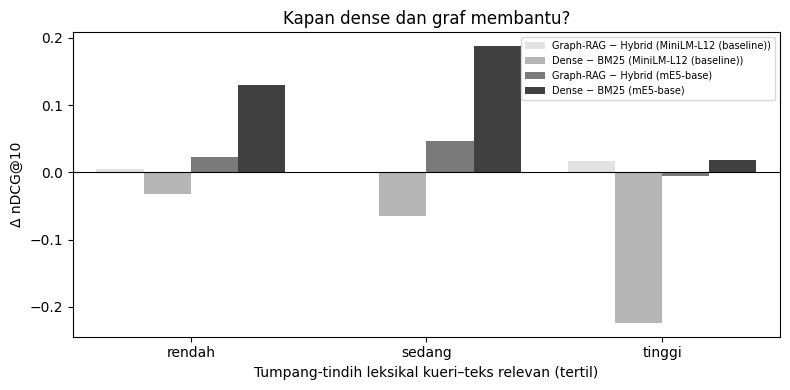

In [ ]:
# Uji di dalam kelompok: di kondisi mana Graph-RAG > Hybrid dan Dense > BM25? (Holm dalam tiap analisis)
UJI_KONDISI = []
for kol in KONDISI:
    d = DETAIL[DETAIL.granularitas == "satuan"].drop(columns="jenis_kueri").merge(FITUR[["kueri_id", kol]], on="kueri_id")
    for kel, dd in d.groupby(kol, observed=True):
        lebar = dd.pivot(index="kueri_id", columns="konfigurasi", values="nDCG@10")
        for e in EMB_BANDING:
            for a_, b_ in [(f"{e} | Graph-RAG", f"{e} | Hybrid"), (f"{e} | Dense", "BM25")]:
                x, y = lebar[a_].to_numpy(), lebar[b_].to_numpy()
                UJI_KONDISI.append({"kondisi": kol, "kelompok": kel, "A": a_, "B": b_, "n": len(x),
                                    "delta": x.mean() - y.mean(), "p_wilcoxon": wilcoxon_aman(x, y)})
UJI_KONDISI = pd.DataFrame(UJI_KONDISI)
UJI_KONDISI["p_holm"] = UJI_KONDISI.groupby("kondisi")["p_wilcoxon"].transform(lambda s: holm(s))
print("Tabel 8. Uji per kondisi (n per kelompok kecil → tafsirkan sebagai eksploratif)")
display(UJI_KONDISI.round(4))

# Gambar: Δ(Graph−Hybrid) dan Δ(Dense−BM25) per kelompok tumpang-tindih leksikal
if "kel_overlap" in KONDISI:
    u = UJI_KONDISI[UJI_KONDISI.kondisi == "kel_overlap"].copy()
    u["kontras"] = (u["A"].str.split(" | ", regex=False).str[-1] + " − " +
                    u["B"].str.split(" | ", regex=False).str[-1] + " (" +
                    u["A"].str.split(" | ", regex=False).str[0] + ")")
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=u, x="kelompok", y="delta", hue="kontras", ax=ax, palette="Greys")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Tumpang-tindih leksikal kueri–teks relevan (tertil)")
    ax.set_ylabel("Δ nDCG@10")
    ax.set_title("Kapan dense dan graf membantu?")
    ax.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "gbr4_kondisi_overlap.png", dpi=300, bbox_inches="tight")
    plt.show()

## §11 — Ablasi Keluarga Sisi Graf (K4)
Untuk embedder pada `ABLASI_EMBEDDERS` dijalankan: graf penuh, *leave-one-out* (tanpa satu keluarga),
dan *single-family* (hanya satu keluarga). Kontribusi satu keluarga = Δ(penuh − tanpa keluarga itu).
Dilengkapi **atribusi**: jumlah satuan relevan di 10 teratas yang masuk lewat tiap keluarga.

In [ ]:
_gr = DETAIL[(DETAIL.granularitas == "satuan") & (DETAIL.pendekatan == "Graph-RAG")].groupby("embedder")["nDCG@10"].mean()
EMB_TERBAIK_GRAF = _gr.idxmax()
emb_ablasi = list(dict.fromkeys(EMB_TERBAIK_GRAF if e == "TERBAIK" else e for e in ABLASI_EMBEDDERS))
VARIAN = {"penuh": SEMUA_SISI}
VARIAN.update({f"tanpa {s}": SEMUA_SISI - {s} for s in sorted(SEMUA_SISI)})
VARIAN.update({f"hanya {s}": frozenset({s}) for s in sorted(SEMUA_SISI)})

ABL = []
for e in emb_ablasi:
    for nv, sisi in VARIAN.items():
        r, _ = jalankan(retrieve_graphrag, e, e, nv, aktif_sisi=sisi)
        ABL += r
    r, _ = jalankan(retrieve_hybrid, e, e, "tanpa graf (Hybrid)")
    ABL += r
ABL = pd.DataFrame(ABL)

TABEL_ABLASI = []
for gran in ("satuan", "pasal"):
    for e in emb_ablasi:
        d = ABL[(ABL.granularitas == gran) & (ABL.embedder == e)]
        lebar = d.pivot(index="kueri_id", columns="pendekatan", values="nDCG@10")
        k = kontras(lebar, [("penuh", v) for v in lebar.columns if v != "penuh"], "ablasi", "nDCG@10")
        k.insert(0, "embedder", e); k.insert(0, "granularitas", gran)
        k["kontribusi (penuh − varian)"] = k["delta"]
        TABEL_ABLASI.append(k)
TABEL_ABLASI = pd.concat(TABEL_ABLASI, ignore_index=True)
print("Tabel 9. Ablasi keluarga sisi (nDCG@10; kontribusi positif = keluarga itu membantu)")
display(TABEL_ABLASI[["granularitas", "embedder", "B", "mean_A", "mean_B", "kontribusi (penuh − varian)",
                      "CI95_lo", "CI95_hi", "p_holm", "naik", "turun"]].rename(columns={"B": "varian"}).round(4))

Tabel 9. Ablasi keluarga sisi (nDCG@10; kontribusi positif = keluarga itu membantu)


,granularitas,embedder,varian,mean_A,mean_B,kontribusi (penuh − varian),CI95_lo,CI95_hi,p_holm,naik,turun
0,satuan,MiniLM-L12 (baseline),hanya memuat,0.3405,0.3329,0.0076,-0.0021,0.0193,1.0000,6,2
1,satuan,MiniLM-L12 (baseline),hanya menyebut,0.3405,0.3261,0.0144,-0.0113,0.0400,1.0000,19,13
2,satuan,MiniLM-L12 (baseline),hanya merujuk,0.3405,0.3284,0.0121,-0.0148,0.0402,1.0000,13,16
3,satuan,MiniLM-L12 (baseline),hanya merujuk_dokumen,0.3405,0.3250,0.0155,-0.0130,0.0450,1.0000,20,13
4,satuan,MiniLM-L12 (baseline),tanpa graf (Hybrid),0.3405,0.3333,0.0072,-0.0198,0.0342,1.0000,19,14
5,satuan,MiniLM-L12 (baseline),tanpa memuat,0.3405,0.3284,0.0121,-0.0148,0.0402,1.0000,13,16
6,satuan,MiniLM-L12 (baseline),tanpa menyebut,0.3405,0.3405,0.0000,0.0000,0.0000,1.0000,0,0
7,satuan,MiniLM-L12 (baseline),tanpa merujuk,0.3405,0.3329,0.0076,-0.0021,0.0193,1.0000,6,2
8,satuan,MiniLM-L12 (baseline),tanpa merujuk_dokumen,0.3405,0.3405,0.0000,0.0000,0.0000,1.0000,0,0
9,satuan,mE5-base,hanya memuat,0.4682,0.4530,0.0151,0.0029,0.0306,0.5638,9,2


Tabel 10. Atribusi hasil graf per keluarga sisi


masuk_top10                                                                    relevan                                                            
embedder        BGE-M3 (dense) Indo-e5-small MiniLM-L12 (baseline) Qwen3-Emb-0.6B mE5-base BGE-M3 (dense) Indo-e5-small MiniLM-L12 (baseline) Qwen3-Emb-0.6B mE5-base
keluarga_sisi                                                                                                                                                        
memuat                      77            77                    92             63       79             16            14                    17             19       25
menyebut                     0             0                     0              0        0              0             0                     0              0        0
merujuk                     14            11                     9              4        5              2             0                     3              1        1
merujuk_dokumen              0             0                     0              0        0              0             0                     0              0        0

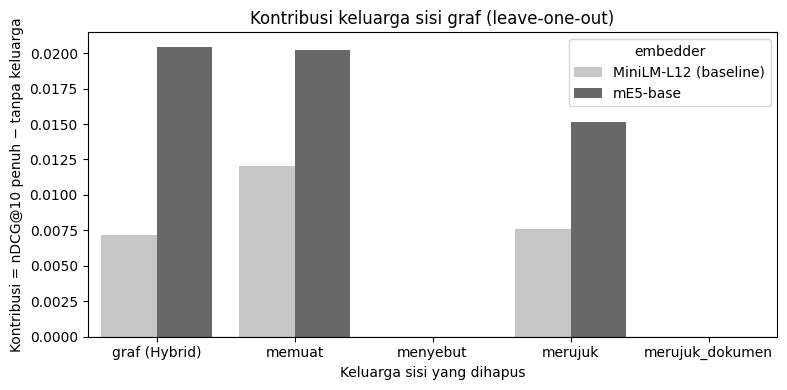

In [ ]:
# Atribusi: dari mana satuan relevan hasil graf berasal (konfigurasi graf penuh, Top-10)
ATRIBUSI = []
for e in EMBEDDER_AKTIF:
    hit = Counter(); muncul = Counter()
    for _, g in gold.iterrows():
        rel = set(g["relevan_list"])
        for c, a in PRED[(e, "Graph-RAG")][g["kueri_id"]]:
            if a.startswith("graf"):
                fam = a.split(":", 1)[1]
                muncul[fam] += 1
                hit[fam] += int(c in rel)
    for fam in sorted(SEMUA_SISI):
        ATRIBUSI.append({"embedder": e, "keluarga_sisi": fam, "masuk_top10": muncul[fam],
                         "relevan": hit[fam], "presisi": hit[fam] / muncul[fam] if muncul[fam] else np.nan})
ATRIBUSI = pd.DataFrame(ATRIBUSI)
print("Tabel 10. Atribusi hasil graf per keluarga sisi")
display(ATRIBUSI.pivot(index="keluarga_sisi", columns="embedder", values=["masuk_top10", "relevan"]))

fig, ax = plt.subplots(figsize=(8, 4))
t = TABEL_ABLASI[(TABEL_ABLASI.granularitas == "satuan") & TABEL_ABLASI.B.str.startswith("tanpa ")].copy()
t["keluarga"] = t["B"].str.replace("tanpa ", "", regex=False)
sns.barplot(data=t, x="keluarga", y="kontribusi (penuh − varian)", hue="embedder", palette="Greys", ax=ax)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Keluarga sisi yang dihapus")
ax.set_ylabel("Kontribusi = nDCG@10 penuh − tanpa keluarga")
ax.set_title("Kontribusi keluarga sisi graf (leave-one-out)")
plt.tight_layout()
plt.savefig(FIG_DIR / "gbr5_ablasi_sisi.png", dpi=300, bbox_inches="tight")
plt.show()

## §12 — Efisiensi (biaya praktis tiap konfigurasi)

In [ ]:
LAT = DETAIL[DETAIL.granularitas == "satuan"].groupby(["embedder", "pendekatan"])["latensi_ms"].mean().unstack()
EFISIENSI = TABEL_EMBEDDER[["dim", "max_seq", "waktu_encode_korpus_s", "ukuran_indeks_MB", "encode_kueri_ms"]].join(
    LAT.drop(index="— (BM25)", errors="ignore").drop(columns="BM25", errors="ignore"))
EFISIENSI.loc["— (BM25)", "BM25"] = LAT.loc["— (BM25)", "BM25"]  # BM25 tidak memakai embedder
print("Tabel 11. Efisiensi (latensi retrieval tidak termasuk encode kueri; Dense/Hybrid memakai cache skor)")
display(EFISIENSI.round(2))

Tabel 11. Efisiensi (latensi retrieval tidak termasuk encode kueri; Dense/Hybrid memakai cache skor)


,dim,max_seq,waktu_encode_korpus_s,ukuran_indeks_MB,encode_kueri_ms,Dense,Graph-RAG,Hybrid,BM25
embedder,,,,,,,,,
MiniLM-L12 (baseline),384.0,128.0,50.5,38.8,0.9,2.21,3.50,0.32,NaN
Indo-e5-small,384.0,128.0,48.2,38.8,0.7,2.37,3.76,0.30,NaN
mE5-base,768.0,512.0,126.1,77.6,1.8,5.71,4.22,0.33,NaN
BGE-M3 (dense),1024.0,512.0,83.2,103.5,1.7,7.34,4.48,0.29,NaN
Qwen3-Emb-0.6B,1024.0,512.0,288.5,103.5,5.4,7.93,4.18,0.29,NaN
— (BM25),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.29


## §13 — Ekspor Seluruh Tabel (siap Bab 4) & Ringkasan Otomatis

In [ ]:
CONFIG = {k: (list(v) if isinstance(v, (set, frozenset, tuple)) else v) for k, v in {
    "RANDOM_SEED": RANDOM_SEED, "K_LIST": K_LIST, "K_KANDIDAT": K_KANDIDAT, "RRF_K": RRF_K, "K_SEED": K_SEED,
    "DECAY": DECAY, "MAKS_PER_SEED": MAKS_PER_SEED, "ALPHA_GRAF": ALPHA_GRAF, "MAX_SEQ_CAP": MAX_SEQ_CAP,
    "N_BOOT": N_BOOT, "EMBEDDERS": {k: v for k, v in EMBEDDERS.items() if k in EMBEDDER_AKTIF},
    "n_kueri": len(gold), "n_korpus": N_KORPUS, "timestamp": TIMESTAMP}.items()}
(EXP_DIR / f"config_{TIMESTAMP}.json").write_text(json.dumps(CONFIG, indent=1, ensure_ascii=False, default=str))

out_xlsx = EXP_DIR / f"hasil_exp04_{TIMESTAMP}.xlsx"
with pd.ExcelWriter(out_xlsx) as xw:
    VALIDASI_GOLD.to_frame("nilai").to_excel(xw, sheet_name="0_validasi_gold")
    pd.Series(STAT_KG).to_frame("nilai").to_excel(xw, sheet_name="0_stat_KG")
    TABEL_EMBEDDER.to_excel(xw, sheet_name="1_embedder")
    tabel_ringkas("satuan").to_excel(xw, sheet_name="2a_hasil_satuan")
    tabel_ringkas("pasal").to_excel(xw, sheet_name="2b_hasil_pasal")
    FRIEDMAN.to_excel(xw, sheet_name="2c_friedman", index=False)
    pd.concat(KONTRAS.values()).to_excel(xw, sheet_name="3_kontras", index=False)
    EFEK.to_excel(xw, sheet_name="4_efek_graf", index=False)
    GRAN.to_excel(xw, sheet_name="5_granularitas")
    UJI_GRAN.to_excel(xw, sheet_name="5b_uji_granularitas", index=False)
    MEKANISME.to_excel(xw, sheet_name="6_mekanisme")
    for kol, t in KONDISI.items():
        t.to_excel(xw, sheet_name=f"7_{kol}"[:31])
    UJI_KONDISI.to_excel(xw, sheet_name="8_uji_kondisi", index=False)
    TABEL_ABLASI.to_excel(xw, sheet_name="9_ablasi", index=False)
    ATRIBUSI.to_excel(xw, sheet_name="10_atribusi", index=False)
    EFISIENSI.to_excel(xw, sheet_name="11_efisiensi")
    FITUR.to_excel(xw, sheet_name="fitur_kueri", index=False)
print("Tersimpan:", out_xlsx)

Tersimpan: /content/drive/MyDrive/Tesis_SDPPI/Project 7/GraphRAG_Komdigi/exp04/hasil_exp04_20261121_1501.xlsx


In [ ]:
# Ringkasan temuan yang DIHITUNG dari hasil (bukan ditulis manual) — salin & sunting untuk Bab 4.
def ringkasan(gran="satuan") -> list:
    t = DETAIL[DETAIL.granularitas == gran].groupby("konfigurasi")["nDCG@10"].mean().sort_values(ascending=False)
    k = KONTRAS[gran]
    out = [f"[{gran}] Konfigurasi terbaik: {t.index[0]} (nDCG@10 = {t.iloc[0]:.3f}); BM25 = {t['BM25']:.3f}; "
           f"baseline Dense MiniLM = {t[f'{BASELINE} | Dense']:.3f}."]
    kb = k[k.keluarga.str.startswith("b") & k.A.str.endswith("| Dense")].sort_values("delta", ascending=False)
    if len(kb):
        r = kb.iloc[0]
        out.append(f"Embedder Dense terbaik relatif terhadap MiniLM: {r.A.split(' | ')[0]} "
                   f"(Δ = {r.delta:+.3f}, CI95 [{r.CI95_lo:.3f}, {r.CI95_hi:.3f}], p_Holm = {r.p_holm:.4f}).")
    e = EFEK[EFEK.granularitas == gran]
    sig = e[e.p_holm_gh < ALPHA]
    out.append(f"Graph-RAG − Hybrid berkisar {e['Δ_graph−hybrid'].min():+.3f} s.d. {e['Δ_graph−hybrid'].max():+.3f}; "
               f"signifikan pada {len(sig)} dari {len(e)} embedder.")
    return out


for gran in ("satuan", "pasal"):
    for s in ringkasan(gran):
        print("•", s)
m = MEKANISME.loc[BASELINE]
print(f"• Mekanisme (baseline): {m['%_hasil_dari_graf']:.1f}% hasil Top-10 berasal dari graf, "
      f"{int(m['TP_graf'])} relevan; {int(m['kueri_diselamatkan'])} kueri diselamatkan vs {int(m['kueri_dirugikan'])} dirugikan.")
ta = TABEL_ABLASI[(TABEL_ABLASI.granularitas == "satuan") & TABEL_ABLASI.B.str.startswith("tanpa ")]
for e_, g_ in ta.groupby("embedder"):
    top = g_.sort_values("delta", ascending=False).iloc[0]
    print(f"• Ablasi ({e_}): keluarga paling berkontribusi = {top.B.replace('tanpa ', '')} "
          f"(Δ = {top.delta:+.3f}, p_Holm = {top.p_holm:.4f}).")

• [satuan] Konfigurasi terbaik: mE5-base | Graph-RAG (nDCG@10 = 0.468); BM25 = 0.346; baseline Dense MiniLM = 0.236.
• Embedder Dense terbaik relatif terhadap MiniLM: mE5-base (Δ = +0.220, CI95 [0.143, 0.293], p_Holm = 0.0001).
• Graph-RAG − Hybrid berkisar -0.014 s.d. +0.020; signifikan pada 0 dari 5 embedder.
• [pasal] Konfigurasi terbaik: BGE-M3 (dense) | Dense (nDCG@10 = 0.573); BM25 = 0.442; baseline Dense MiniLM = 0.354.
• Embedder Dense terbaik relatif terhadap MiniLM: BGE-M3 (dense) (Δ = +0.219, CI95 [0.120, 0.315], p_Holm = 0.0021).
• Graph-RAG − Hybrid berkisar -0.003 s.d. +0.019; signifikan pada 0 dari 5 embedder.
• Mekanisme (baseline): 42.8% hasil Top-10 berasal dari graf, 33 relevan; 0 kueri diselamatkan vs 1 dirugikan.
• Ablasi (MiniLM-L12 (baseline)): keluarga paling berkontribusi = memuat (Δ = +0.012, p_Holm = 1.0000).
• Ablasi (mE5-base): keluarga paling berkontribusi = graf (Hybrid) (Δ = +0.020, p_Holm = 0.5638).


## §14 — Kesimpulan & Keterbatasan (lengkapi setelah dijalankan)

**Temuan** (gunakan keluaran §13; jangan menulis angka yang tidak berasal dari notebook):
1. K1 — …
2. K2 — … (sebutkan apakah nilai tambah graf mengecil/membesar ketika embedder membaik)
3. K3 — …
4. K4 — …

**Keterbatasan yang wajib ditulis:**
* Gold standard 46 kueri ditulis oleh peneliti yang mengenal kosakata korpus → bias leksikal yang
  menguntungkan BM25; subset kueri awam (§2) dianjurkan untuk mengujinya.
* Banyak kontras → koreksi Holm dipakai; analisis per kondisi (§10) bersifat eksploratif karena n per kelompok kecil.
* Batas token dibatasi 512 untuk semua model berkonteks panjang demi keadilan dan memori GPU; BGE-M3
  hanya keluaran dense (keluaran sparse/multi-vector tidak dievaluasi).
* Hyperparameter Graph-RAG (decay, α, bobot sisi) diwarisi dari Exp_03 dan tidak dituning per embedder.
* Penempatan di tesis: §3 → Bab 3 (metodologi evaluasi); Tabel 1–11 dan Gambar 1–5 → Bab 4.